# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [44]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Цимбалюк Антон'      # прізвище та ім'я
GROUP        = 'ШІ-34'               # шифр групи, наприклад СШІ-31
NUMBER       = 15                    # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Цимбалюк Антон | ШІ-34 | номер 15


In [45]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 15   ·   Цимбалюк Антон   ·   ШІ-34

   Ринок:  Lviv
   Товар:  олія   (у наборі даних: Oil (sunflower) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

In [46]:
%pip install statsmodels


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [47]:
# ── Спільні імпорти та налаштування для всієї роботи ──
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

mpl.rcParams['font.family'] = 'DejaVu Sans'
mpl.rcParams['figure.figsize'] = (11, 3.6)
mpl.rcParams['axes.grid'] = True
mpl.rcParams['grid.alpha'] = 0.25
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.right'] = False

# Жорстко задані методичкою параметри — від них залежить зіставність із Orange
START, END = '2014-03-01', '2017-12-01'
N_FOLDS, HORIZON = 7, 3
ARIMA_ORDER = (1, 1, 1)

print(f'Ряд: {MARKET} · {GOOD_UA}')
print(f'Перевірка: {N_FOLDS} фолдів × {HORIZON} кроки · ARIMA{ARIMA_ORDER}')

Ряд: Lviv · олія
Перевірка: 7 фолдів × 3 кроки · ARIMA(1, 1, 1)


## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [48]:
# Завдання 1. Підготовка ряду
prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
         .sort_values('date').set_index('date')['ціна'])

# Повна місячна сітка — будуємо її НЕ з даних, а з умови задачі.
# Інакше пропуск у кінці чи на початку ряду просто не з'явиться.
grid = pd.date_range(START, END, freq='MS')
series = raw.reindex(grid)
series.index.freq = 'MS'

print(f'Місяців у сітці          : {len(grid)}')
print(f'Місяців із виміром       : {int(series.notna().sum())}')
print(f'Пропусків                : {int(series.isna().sum())}')
print(f'Дублікатів дат у сирому  : {int(raw.index.duplicated().sum())}')
print()
gaps = series.index[series.isna()]
print('Пропуск у місяці:', ', '.join(d.strftime('%m.%Y') for d in gaps))
print()
print('Сусідні значення:')
for d in gaps:
    i = series.index.get_loc(d)
    print(f'   {series.index[i-1]:%m.%Y} = {series.iloc[i-1]:.4f}   '
          f'[{d:%m.%Y} = ПРОПУСК]   {series.index[i+1]:%m.%Y} = {series.iloc[i+1]:.4f}')

Місяців у сітці          : 46
Місяців із виміром       : 45
Пропусків                : 1
Дублікатів дат у сирому  : 0

Пропуск у місяці: 08.2017

Сусідні значення:
   07.2017 = 31.4133   [08.2017 = ПРОПУСК]   09.2017 = 31.6167


In [49]:
# Чому пропуск виник: перевіряємо, чи він лише в нашому ряді, чи в усьому наборі
by_month = prices.groupby('date').size().reindex(grid).fillna(0).astype(int)

print('Кількість записів у ВСЬОМУ наборі по місяцях (мін. / макс. / нулі):')
print(f'   мінімум не рахуючи нулів: {by_month[by_month > 0].min()}')
print(f'   максимум                : {by_month.max()}')
print(f'   місяці з нулем записів  : '
      f'{", ".join(d.strftime("%m.%Y") for d in by_month.index[by_month == 0])}')
print()
print('Отже, у цьому місяці немає жодного спостереження по ЖОДНОМУ з 28 ринків')
print('і ЖОДНОМУ з 25 товарів — це пропуск збору даних, а не властивість нашого ряду.')

Кількість записів у ВСЬОМУ наборі по місяцях (мін. / макс. / нулі):
   мінімум не рахуючи нулів: 599
   максимум                : 699
   місяці з нулем записів  : 08.2017

Отже, у цьому місяці немає жодного спостереження по ЖОДНОМУ з 28 ринків
і ЖОДНОМУ з 25 товарів — це пропуск збору даних, а не властивість нашого ряду.


**Висновок до завдання 1:**

У місячній сітці з 03.2014 по 12.2017 — **46 місяців**, вимір є у **45** із них.
Єдиний пропуск — **серпень 2017 року** (41-ша позиція ряду з 46); сусідні значення
31.4133 грн (07.2017) і 31.6167 грн (09.2017).

Пропуск у ряді **один**. Я спеціально будував сітку з умови задачі (`pd.date_range`),
а не з наявних дат: якби сітку було виведено з самих даних, цього пропуску просто
не існувало б — ряд мав би 45 поспіль розташованих точок, і діра була б невидима.

**Причина пропуску не в нашому ряді.** Остання клітинка показує, що за серпень 2017
у всьому наборі **нуль записів** — ні по жодному з 28 ринків, ні по жодному з 25 товарів,
тоді як у решті місяців їх 599–650. Це пропуск у зборі даних на боці постачальника
(World Food Programme не оприлюднив місячний зріз), а не відсутність торгівлі олією
у Львові в серпні 2017. Саме тому заповнювати його інтерполяцією коректно: подія
«ціна в серпні 2017» існувала, не записаним лишилося лише її вимірювання.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [50]:
# Завдання 2. Заповнення пропуску
g = gaps[0]                       # місяць пропуску
i = series.index.get_loc(g)

methods = {
    'перенесення вперед (ffill)':   series.ffill(),
    'перенесення назад (bfill)':    series.bfill(),
    'лінійна інтерполяція':         series.interpolate(method='linear'),
    'середнє ковзне вікно ±3 міс.': series.rolling(7, center=True, min_periods=3).mean(),
    'сезонний наївний (той самий місяць торік)': series.shift(12),
}

print(f'Значення для {g:%m.%Y} за різними способами:')
print(f'{"спосіб":<44}{"значення":>10}{"відхил. від лінійної":>24}')
print('-' * 78)
lin = series.interpolate(method='linear').loc[g]
for name, ser in methods.items():
    v = ser.loc[g]
    print(f'{name:<44}{v:>10.4f}{v - lin:>+24.4f}')

Значення для 08.2017 за різними способами:
спосіб                                        значення    відхил. від лінійної
------------------------------------------------------------------------------
перенесення вперед (ffill)                     31.4133                 -0.1017
перенесення назад (bfill)                      31.6167                 +0.1017
лінійна інтерполяція                           31.5150                 +0.0000
середнє ковзне вікно ±3 міс.                   31.5961                 +0.0811
сезонний наївний (той самий місяць торік)      33.5700                 +2.0550


In [51]:
# Обраний спосіб — лінійна інтерполяція
f = series.interpolate(method='linear')
f.index.freq = 'MS'

print(f'Заповнено: {g:%m.%Y} = {f.loc[g]:.4f} грн')
print(f'Пропусків лишилося: {int(f.isna().sum())}   Довжина ряду: {len(f)}')
print()
# Наскільки взагалі «коштує» вибір способу в цьому місці ряду
method_spread = max(s.loc[g] for s in methods.values()) - min(s.loc[g] for s in methods.values())
print(f'Розмах між найбільшим і найменшим способом: {method_spread:.4f} грн '
      f'({100*method_spread/f.median():.1f} % від медіани ряду)')
print(f'Типова місячна зміна ряду в 2017 році     : '
      f'{f.loc["2017"].diff().abs().mean():.4f} грн')

Заповнено: 08.2017 = 31.5150 грн
Пропусків лишилося: 0   Довжина ряду: 46

Розмах між найбільшим і найменшим способом: 2.1567 грн (6.9 % від медіани ряду)
Типова місячна зміна ряду в 2017 році     : 0.4352 грн


In [52]:
# Коли заповнювати НЕ можна: ринки, які зникають із набору
coverage = (prices.groupby('ринок')['date'].agg(['min', 'max', 'count'])
             .sort_values('max'))
truncated = coverage[coverage['max'] < pd.Timestamp(END)]
print('Ринки, записи про які обриваються до кінця періоду:')
print(truncated.to_string())
print()
print(f'Решта {len(coverage) - len(truncated)} ринків мають записи до {END[:7]}.')

Ринки, записи про які обриваються до кінця періоду:
                     min        max  count
ринок                                     
Crimea        2014-03-01 2014-03-01     25
m. Sevastopol 2014-03-01 2014-04-01     50

Решта 26 ринків мають записи до 2017-12.


**Висновок до завдання 2:**

**1. Значення за способами.** Перенесення вперед дає 31.4133, назад — 31.6167,
лінійна інтерполяція — **31.5150**, ковзне середнє ±3 міс. — 31.5961, сезонний
наївний (серпень 2016) — 33.5700.

**2. Обрано лінійну інтерполяцію.** Підстави такі. По-перше, пропуск стоїть
усередині ряду й має обидва сусідні виміри, які майже збігаються (31.41 і 31.62) —
лінійна інтерполяція між ними це просто їхнє середнє й не вносить жодного припущення
про форму. По-друге, вся невизначеність тут мізерна: розмах між найкрайнішими
способами — 2.16 грн, але 2.09 грн із них дає **сезонний наївний**, який помилково
тягне значення серпня 2016 року, коли ряд стояв на рівні 33.6 грн; якщо його
відкинути, розмах чотирьох решти способів становить лише 0.18 грн при типовій
місячній зміні ряду в 2017 році 0.12 грн. Тобто вибір способу тут практично не
впливає на подальший аналіз. По-третє, сезонний наївний непридатний принципово:
у завданні 4 я показую, що стабільної річної сезонності в цьому ряді немає, тож
переносити значення «того самого місяця торік» немає підстав.

**3. Коли заповнювати неприпустимо.** У цьому ж наборі є два такі ринки: **Crimea**
(останній запис 03.2014) та **m. Sevastopol** (останній запис 04.2014). Там
порожні клітинки після цих дат — не пропуск вимірювання, а **кінець ряду**:
ці території вибули зі статистичного спостереження України після анексії. Заповнити
їх інтерполяцією означало б вигадати ціни для ринку, якого в наборі більше немає,
і отримати ряд, кожне значення якого після 04.2014 є чистою конструкцією.
Загальне правило: заповнювати можна лише тоді, коли подія відбулася, а не записане
саме вимірювання; коли ж відсутній сам об'єкт спостереження — ряд треба обривати.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

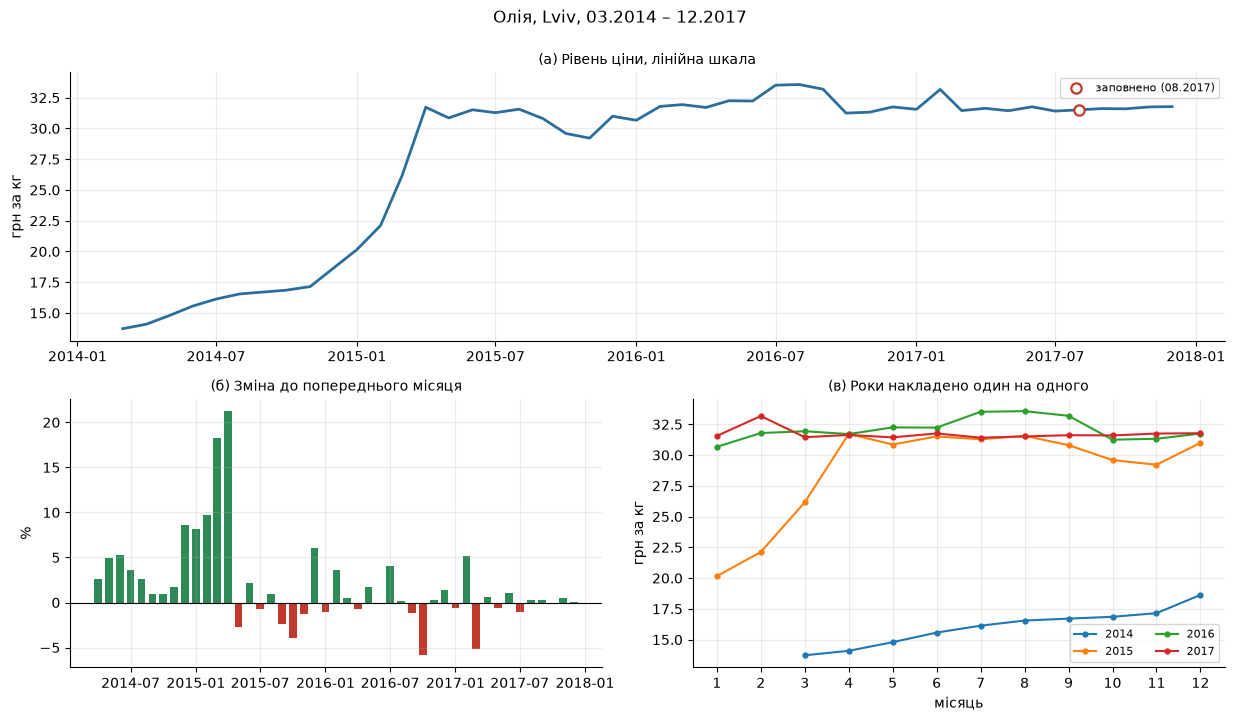

In [53]:
# Завдання 3. Візуальна розвідка
fig = plt.figure(figsize=(12.5, 7.2))
gs = fig.add_gridspec(2, 2)
axes = [fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]
fig.suptitle(f'{GOOD_UA.capitalize()}, {MARKET}, 03.2014 – 12.2017', fontsize=12, y=0.995)

# (а) рівні, лінійна шкала — як змінювався рівень у гривнях
ax = axes[0]
ax.plot(f.index, f.values, lw=2, color='#2C6E9B')
ax.scatter([g], [f.loc[g]], s=55, facecolor='white', edgecolor='#C0392B',
           zorder=5, lw=1.6, label=f'заповнено ({g:%m.%Y})')
ax.set_title('(а) Рівень ціни, лінійна шкала', fontsize=10)
ax.set_ylabel('грн за кг'); ax.legend(fontsize=8)

# (б) місячні зміни — коли були удари і наскільки ряд мінливий
ax = axes[1]
changes = f.pct_change().dropna() * 100
ax.bar(changes.index, changes.values, width=22,
       color=np.where(changes.values >= 0, '#2E8B57', '#C0392B'))
ax.axhline(0, color='k', lw=0.8)
ax.set_title('(б) Зміна до попереднього місяця', fontsize=10)
ax.set_ylabel('%')

# (в) накладання років — чи повторюється форма
ax = axes[2]
piv = pd.DataFrame({'м': f.index.month, 'р': f.index.year, 'v': f.values}) \
        .pivot_table(index='м', columns='р', values='v')
for year in piv.columns:
    ax.plot(piv.index, piv[year], marker='o', ms=3.5, lw=1.5, label=str(year))
ax.set_xticks(range(1, 13))
ax.set_title('(в) Роки накладено один на одного', fontsize=10)
ax.set_xlabel('місяць'); ax.set_ylabel('грн за кг'); ax.legend(fontsize=8, ncol=2)

plt.tight_layout(); plt.show()

In [54]:
# Числа, що стоять за знахідкою з графіка (б): мінливість падає з часом
regimes = [('04.2014–03.2015', '2014-04', '2015-03'),
          ('04.2015–06.2016', '2015-04', '2016-06'),
          ('07.2016–12.2017', '2016-07', '2017-12')]
print(f'{"період":<18}{"n":>3}{"сер.|зміна|":>13}{"ст.відх.":>10}{"розмах":>18}')
print('-' * 62)
for name, a, b in regimes:
    x = changes.loc[a:b]
    print(f'{name:<18}{len(x):>3}{x.abs().mean():>12.2f}%{x.std():>9.2f}%'
          f'{f"[{x.min():+.1f}%, {x.max():+.1f}%]":>18}')
print()
print(f'Зростання 03.2014 → 03.2015: {100*(f.loc["2015-03-01"]/f.loc["2014-03-01"]-1):+.1f} %  (за 12 міс.)')
print(f'Зростання 03.2015 → 12.2017: {100*(f.loc["2017-12-01"]/f.loc["2015-03-01"]-1):+.1f} %  (за 33 міс.)')

період              n  сер.|зміна|  ст.відх.            розмах
--------------------------------------------------------------
04.2014–03.2015    12        5.63%     5.00%   [+0.9%, +18.3%]
04.2015–06.2016    15        3.28%     6.02%   [-3.9%, +21.2%]
07.2016–12.2017    18        1.57%     2.55%    [-5.9%, +5.1%]

Зростання 03.2014 → 03.2015: +90.6 %  (за 12 міс.)
Зростання 03.2015 → 12.2017: +21.5 %  (за 33 міс.)


**Висновок до завдання 3:**

**(а) Рівень ціни, лінійна шкала.** Питання: *на скільки гривень змінилася ціна і коли?*
Геометрія — лінія, бо спостереження впорядковані в часі й сусідні точки пов'язані;
саме неперервна лінія стверджує цю пов'язаність, тоді як стовпчики стверджували б
незалежність категорій. Шкала лінійна і **не починається з нуля**: питання тут про
зміну рівня, а не про порівняння величин між собою, тож нульова база лише стиснула б
корисний діапазон. Панель розтягнуто на всю ширину, бо це головний графік ряду,
з яким звіряються решта панелей і Line Chart у Orange (завдання 11). Порожнім
кружком позначено заповнений серпень 2017 — читач має бачити, де в ряді є
сконструйоване значення.

**(б) Зміна до попереднього місяця.** Питання: *коли саме відбувалися удари і
наскільки ряд мінливий?* Тут геометрія вже стовпчикова й база обов'язково нульова:
нуль має природний зміст «ціна не змінилася», а знак зміни несе інформацію, тому
стовпчики розфарбовано за знаком. Диференціювання прибирає тренд, який домінує на
графіку (а), і дає побачити структуру, яку той приховує.

**(в) Роки накладено один на одного.** Питання: *чи повторюється форма ряду
з року в рік?* Це прямий візуальний тест на сезонність: якби вона була, криві
років мали б однакову форму, відрізняючись лише вертикальним зсувом. Вони її
не мають — 2014 рік монотонно зростає, 2016 має горб улітку, 2017 майже
горизонтальний.

**Несподівана знахідка.** Я очікував побачити тренд, але не очікував настільки
різкого **падіння мінливості**: середня абсолютна місячна зміна знижується з 5.63 %
у 2014–2015 роках до 3.28 %, а далі до 1.57 % у 2016–2017; стандартне відхилення
падає з 5.00 % до 2.55 %. Ряд не просто зростає — він проходить через ударний період
і «замерзає» на рівні 31–33 грн, де місячні коливання становлять лічені копійки.
Це означає, що дисперсія ряду **непостійна в часі**, і будь-яка модель із припущенням
про сталу дисперсію описуватиме початок і кінець ряду по-різному погано. Друге, чого
я не очікував: 90.6 % усього зростання ціни припадає на перші 12 місяців ряду, а на
решту 33 місяці — лише 21.5 %.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

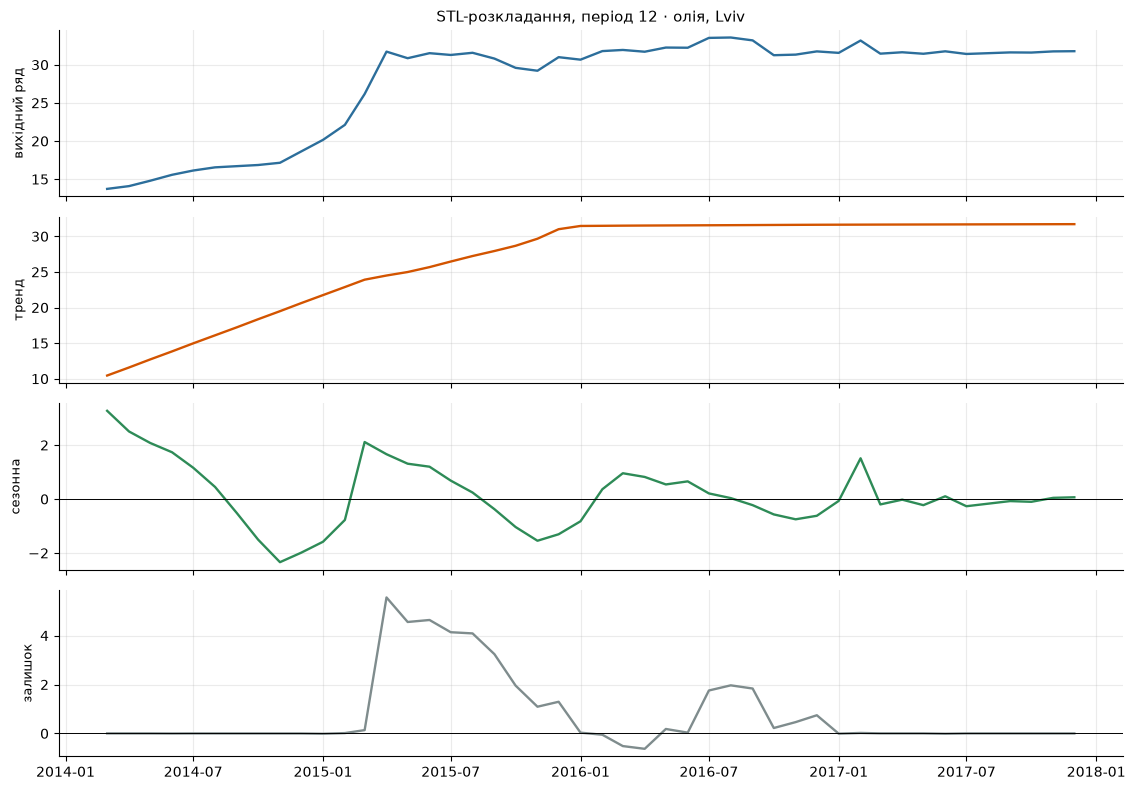

Var(залишок)          = 2.37233
Var(сезонна+залишок)  = 4.27256
Var(тренд+залишок)    = 48.21334

F_S = 0.4448   (поріг 0.3)
F_T = 0.9508   (поріг 0.3)

Амплітуда сезонної складової: 5.610 грн (17.8 % від медіани ряду)


In [55]:
# Завдання 4. Розкладання на складові
stl = STL(f, period=12, robust=True).fit()
T, S, R = stl.trend, stl.seasonal, stl.resid

fig, axes = plt.subplots(4, 1, figsize=(11.5, 8), sharex=True)
for ax, data, name, color in [
        (axes[0], f, 'вихідний ряд', '#2C6E9B'),
        (axes[1], T, 'тренд',        '#D35400'),
        (axes[2], S, 'сезонна',      '#2E8B57'),
        (axes[3], R, 'залишок',      '#7F8C8D')]:
    ax.plot(data.index, data.values, lw=1.7, color=color)
    ax.set_ylabel(name, fontsize=9)
axes[2].axhline(0, color='k', lw=0.7)
axes[3].axhline(0, color='k', lw=0.7)
axes[0].set_title(f'STL-розкладання, період 12 · {GOOD_UA}, {MARKET}', fontsize=11)
plt.tight_layout(); plt.show()

# Сила сезонності та сила тренду
F_S = max(0.0, 1 - R.var() / (S + R).var())
F_T = max(0.0, 1 - R.var() / (T + R).var())
print(f'Var(залишок)          = {R.var():.5f}')
print(f'Var(сезонна+залишок)  = {(S + R).var():.5f}')
print(f'Var(тренд+залишок)    = {(T + R).var():.5f}')
print()
print(f'F_S = {F_S:.4f}   (поріг 0.3)')
print(f'F_T = {F_T:.4f}   (поріг 0.3)')
print()
print(f'Амплітуда сезонної складової: {S.max() - S.min():.3f} грн '
      f'({100*(S.max() - S.min())/f.median():.1f} % від медіани ряду)')

In [56]:
# F_S сам по собі нічого не доводить. Три незалежні перевірки стабільності сезонної складової.

# (1) Чи однакова сезонна складова для того самого місяця в різні роки?
seas = pd.DataFrame({'м': S.index.month, 'р': S.index.year, 'v': S.values}) \
        .pivot_table(index='м', columns='р', values='v')
print('Сезонна складова STL для того самого місяця, грн:')
print(seas.round(2).to_string())
print()
print(f'Середній розкид (max−min) однієї місячної позиції між роками: '
      f'{seas.apply(lambda r: r.max() - r.min(), axis=1).mean():.2f} грн')
print(f'Амплітуда самої складової                                    : '
      f'{S.max() - S.min():.2f} грн')
print()

# (2) Чи корелює ФОРМА одного року з формою наступного?
print('Кореляція форми сусідніх років (рівень знято відніманням річного середнього):')
for a, b, mon in [(2014, 2015, 3), (2015, 2016, 3), (2016, 2017, 1)]:
    sel = piv.index >= mon
    x = piv.loc[sel, a] - piv.loc[sel, a].mean()
    y = piv.loc[sel, b] - piv.loc[sel, b].mean()
    print(f'   {a} vs {b} (місяці {mon}–12):  r = {x.corr(y):+.3f}')

Сезонна складова STL для того самого місяця, грн:
р   2014  2015  2016  2017
м                         
1    NaN -1.58 -0.82 -0.07
2    NaN -0.77  0.36  1.51
3   3.27  2.11  0.96 -0.20
4   2.50  1.66  0.82 -0.02
5   2.08  1.31  0.54 -0.23
6   1.73  1.20  0.66  0.10
7   1.16  0.68  0.21 -0.27
8   0.45  0.24  0.03 -0.17
9  -0.52 -0.38 -0.23 -0.08
10 -1.50 -1.04 -0.57 -0.10
11 -2.34 -1.55 -0.75  0.04
12 -1.99 -1.30 -0.62  0.07

Середній розкид (max−min) однієї місячної позиції між роками: 1.84 грн
Амплітуда самої складової                                    : 5.61 грн

Кореляція форми сусідніх років (рівень знято відніманням річного середнього):
   2014 vs 2015 (місяці 3–12):  r = +0.290
   2015 vs 2016 (місяці 3–12):  r = +0.397
   2016 vs 2017 (місяці 1–12):  r = -0.203


**Висновок до завдання 4:**

**Числа.** $F_S = 0.4448$, $F_T = 0.9508$. Амплітуда сезонної складової 5.610 грн,
тобто 17.8 % від медіани ряду.

**Формально $F_S = 0.44 > 0.3$, тобто за критерієм методички сезонна складова є.
Але спиратися на це число в цьому ряді не можна, і ось три незалежні причини.**

*По-перше, «сезонна» складова не повторюється — вона згасає.* Для березня STL дає
+3.27, +2.11, +0.96 і −0.20 грн у 2014, 2015, 2016 і 2017 роках відповідно; для
листопада −2.34, −1.55, −0.75, +0.04. Це монотонне згасання до нуля, а не
повторення. Середній розкид однієї й тієї самої місячної позиції між роками
становить 1.84 грн при амплітуді самої складової 5.61 грн — тобто розкид сягає
третини амплітуди. Справжня сезонність виглядає інакше: та сама форма, той самий
знак, рік у рік.

*По-друге, форма років між собою не корелює.* Кореляція форми 2014 з 2015 дає
r = +0.29, 2015 з 2016 — r = +0.40, а 2016 з 2017 — **r = −0.20**. Знак змінюється.
Якби річний цикл існував, усі три кореляції були б високими й додатними.

*По-третє, сезонний наївний прогноз програє.* У завданні 6 метод «візьми значення
того самого місяця торік» дає MAE 1.139 проти 0.626 у звичайного наївного — тобто
вдвічі гірше. Якби сезонність була, використання торішнього місяця допомагало б,
а не шкодило.

**Що насправді виділив STL.** Ряд має один різкий зсув рівня на початку 2015 року
(завдання 8). STL із періодом 12 не має механізму описати разовий зсув, тож частина
його потрапляє в сезонну складову й далі згасає в міру того, як loess-згладжування
тренду «наздоганяє» новий рівень. Саме це й бачимо в таблиці: складова найбільша
в 2014 році, біля зсуву, і майже нульова в 2017-му.

**Підсумок: сезонності у ряді немає.** Велике $F_T = 0.95$ при цьому цілком
правдиве — тренд справді домінує й пояснює майже всю варіацію ряду. Саме тому в
завданнях 6–7 я не розглядаю сезонні моделі як серйозних кандидатів.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

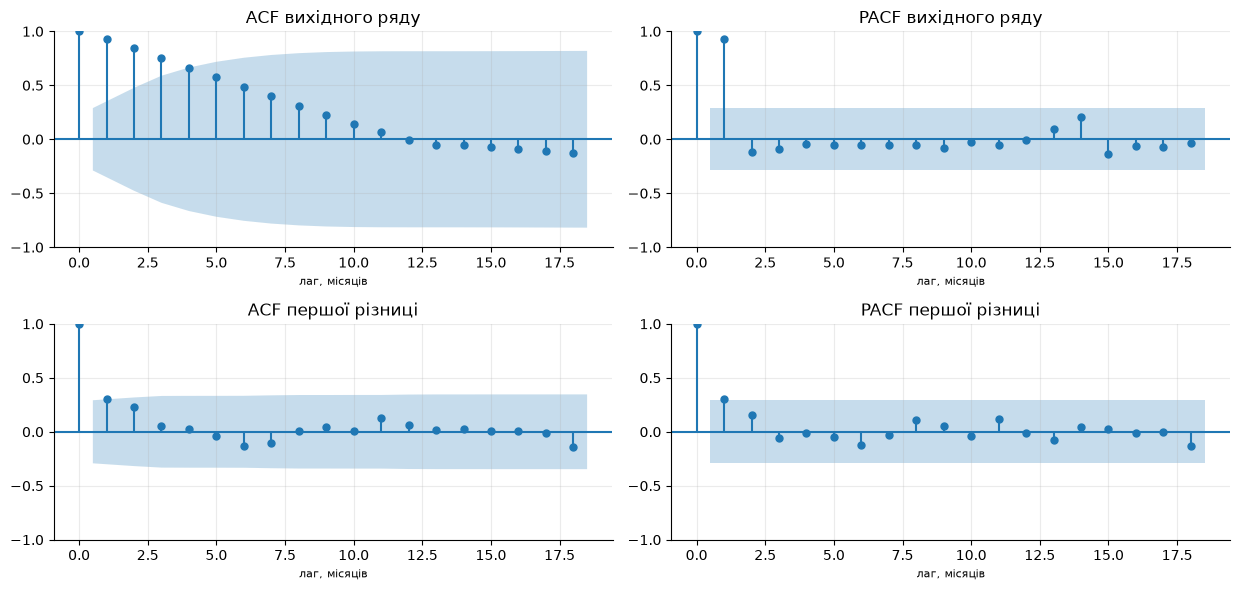

In [57]:
# Завдання 5. Стаціонарність
d1 = f.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(12.5, 6))
plot_acf(f,  lags=18, ax=axes[0, 0], title='ACF вихідного ряду')
plot_pacf(f, lags=18, ax=axes[0, 1], title='PACF вихідного ряду', method='ywm')
plot_acf(d1, lags=18, ax=axes[1, 0], title='ACF першої різниці')
plot_pacf(d1, lags=18, ax=axes[1, 1], title='PACF першої різниці', method='ywm')
for ax in axes.ravel():
    ax.set_xlabel('лаг, місяців', fontsize=8)
plt.tight_layout(); plt.show()

In [58]:
# Тести стаціонарності. Нульові гіпотези ПРОТИЛЕЖНІ — тримаємо їх перед очима.
rows = []
for name, x in [('рівні', f), ('1-ша різниця', d1)]:
    a = adfuller(x, autolag='AIC')
    k = kpss(x, regression='c', nlags='auto')
    rows.append({
        'ряд': name,
        'ADF стат.': round(a[0], 3), 'ADF p': round(a[1], 4),
        'ADF висновок': 'нестаціонарний' if a[1] > 0.05 else 'стаціонарний',
        'KPSS стат.': round(k[0], 3), 'KPSS p': round(k[1], 4),
        'KPSS висновок': 'нестаціонарний' if k[1] < 0.05 else 'стаціонарний',
    })
tab5 = pd.DataFrame(rows)
print('H0 ADF : ряд НЕстаціонарний  ->  мале p = стаціонарність')
print('H0 KPSS: ряд стаціонарний    ->  мале p = НЕстаціонарність')
print()
print(tab5.to_string(index=False))
print()
print('Примітка: p-значення KPSS обрізані таблицею критичних значень')
print('(0.01 і 0.10 — це межі таблиці, а не точні значення).')
print()
bound = 1.96 / np.sqrt(len(d1))
sig_acf  = [i+1 for i, v in enumerate(acf(d1, nlags=12)[1:])  if abs(v) > bound]
sig_pacf = [i+1 for i, v in enumerate(pacf(d1, nlags=12)[1:], ) if abs(v) > bound]
print(f'Межа значущості для n={len(d1)}: ±{bound:.3f}')
print(f'Значущі лаги ACF  першої різниці: {sig_acf}   (значення: {acf(d1, nlags=3)[1:].round(3)})')
print(f'Значущі лаги PACF першої різниці: {sig_pacf}   (значення: {pacf(d1, nlags=3)[1:].round(3)})')

H0 ADF : ряд НЕстаціонарний  ->  мале p = стаціонарність
H0 KPSS: ряд стаціонарний    ->  мале p = НЕстаціонарність

         ряд  ADF стат.  ADF p   ADF висновок  KPSS стат.  KPSS p  KPSS висновок
       рівні     -2.337 0.1603 нестаціонарний       0.743    0.01 нестаціонарний
1-ша різниця     -4.731 0.0001   стаціонарний       0.335    0.10   стаціонарний

Примітка: p-значення KPSS обрізані таблицею критичних значень
(0.01 і 0.10 — це межі таблиці, а не точні значення).

Межа значущості для n=45: ±0.292
Значущі лаги ACF  першої різниці: [1]   (значення: [0.303 0.231 0.057])
Значущі лаги PACF першої різниці: [1]   (значення: [ 0.31   0.162 -0.059])


**Висновок до завдання 5:**

> **Коротко:** ціна олії нестаціонарна, а її місячна зміна стаціонарна, тому ряд
> треба один раз продиференціювати (**d = 1**). Обидва тести, ADF і KPSS, кажуть одне й те саме.

| ряд | ADF стат. | ADF p | висновок ADF | KPSS стат. | KPSS p | висновок KPSS |
|---|---|---|---|---|---|---|
| рівні | −2.337 | 0.1603 | нестаціонарний | 0.743 | 0.0100 | нестаціонарний |
| 1-ша різниця | −4.731 | 0.0001 | стаціонарний | 0.335 | 0.1000 | стаціонарний |

**Напрямок висновків.** Нульова гіпотеза ADF — ряд **нестаціонарний**, тому p = 0.1603
на рівнях означає, що нестаціонарність **не відхилено**. Нульова гіпотеза KPSS
протилежна — ряд **стаціонарний**, тому p = 0.01 означає, що стаціонарність
**відхилено**. Обидва тести кажуть те саме різними словами.

**Тести узгоджуються, причому на обох рядах.** На рівнях обидва вказують на
нестаціонарність, на першій різниці обидва — на стаціонарність. Це найчистіший
із можливих результатів: він однозначно дає **d = 1**, і саме тому порядок
інтегрування в ARIMA(1,1,1) є виправданим (на відміну від p і q — див. завдання 7).

**Що видно з корелограм.** ACF рівнів згасає повільно й майже лінійно
(0.928, 0.845, 0.755, 0.665 …), а PACF обривається після першого лага зі значенням
0.949, близьким до одиниці — класична картина випадкового блукання. Після
диференціювання картина змінюється повністю: при межі значущості ±0.292 значущим
лишається **лише лаг 1** — ACF(1) = 0.303 і PACF(1) = 0.310, усі наступні лаги
в межах шуму. Сезонного піку на лагу 12 немає ні до, ні після диференціювання,
що незалежно підтверджує висновок завдання 4.

**Застереження.** p-значення KPSS обрізані межами таблиці критичних значень:
0.0100 означає «не більше за 0.01», а 0.1000 — «не менше за 0.10». Statsmodels
попереджає про це явно. На висновок це не впливає, бо обидва значення лежать
далеко від порога 0.05.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [59]:
# Завдання 6. Ретроспективна перевірка з рухомим початком
#
# Порядок фолдів узято з методички й він збігається з тим, що робить Orange:
# для фолду f навчальна частина — це все до позиції −ГОРИЗОНТ·f,
# перевіряються наступні ГОРИЗОНТ спостережень.
y = f.values

def backtest(fc_fun):
    """Повертає (істина, прогноз, номер_фолда) у тому самому порядку, що й Orange."""
    y_true, y_hat, folds = [], [], []
    for fold in range(1, N_FOLDS + 1):
        bound = -fold * HORIZON
        train = y[:bound]
        y_hat.extend(fc_fun(train, HORIZON))
        y_true.extend(y[bound:][:HORIZON])   # зріз двічі: y[-3:0] дало б порожньо
        folds.extend([fold] * HORIZON)
    return np.array(y_true), np.array(y_hat), np.array(folds)

naive   = lambda train, h: np.repeat(train[-1], h)
snaive  = lambda train, h: np.array([train[-12 + i] if len(train) >= 12 else train[-1]
                                     for i in range(h)])
mean_fc = lambda train, h: np.repeat(train.mean(), h)
def drift(train, h):
    slope = (train[-1] - train[0]) / (len(train) - 1)
    return train[-1] + slope * np.arange(1, h + 1)

def metrics(y_true, y_pred):
    e = y_true - y_pred
    return dict(MAE=np.mean(np.abs(e)),
                RMSE=np.sqrt(np.mean(e ** 2)),
                MAPE=100 * np.mean(np.abs(e / y_true)))

BASELINES = {'наївний': naive, 'сезонний наївний': snaive,
             'середнє': mean_fc, 'дрейф': drift}
results = {}
for name, fn in BASELINES.items():
    y_true, y_pred, folds = backtest(fn)
    results[name] = (y_true, y_pred, metrics(y_true, y_pred))

tab6 = pd.DataFrame({k_: v_[2] for k_, v_ in results.items()}).T.round(4)
tab6.index.name = 'базис'
print(f'Ретроспективна перевірка: {N_FOLDS} фолдів × {HORIZON} кроки = '
      f'{N_FOLDS * HORIZON} перевірених спостережень')
print(f'Перевірено місяці: {f.index[-N_FOLDS*HORIZON]:%m.%Y} – {f.index[-1]:%m.%Y}')
print()
print(tab6.to_string())
print()
best = tab6['MAE'].idxmin()
print(f'Найкращий за MAE: {best}')

Ретроспективна перевірка: 7 фолдів × 3 кроки = 21 перевірених спостережень
Перевірено місяці: 04.2016 – 12.2017

                     MAE    RMSE     MAPE
базис                                    
наївний           0.6261  0.8862   1.9441
сезонний наївний  1.1393  1.3841   3.5429
середнє           5.9812  6.1905  18.6284
дрейф             1.2539  1.5331   3.9495

Найкращий за MAE: наївний


In [60]:
# Чому наївний: подивимось, наскільки ряд схожий на випадкове блукання
# у тій частині, яку перевіряє бектест.
test_part = f.iloc[-N_FOLDS * HORIZON:]
print(f'Перевірювана частина ряду ({len(test_part)} міс.): '
      f'min={test_part.min():.2f}  max={test_part.max():.2f}  розмах={test_part.max()-test_part.min():.2f} грн')
print(f'Середня |місячна зміна| в ній: {test_part.diff().abs().mean():.3f} грн')
print(f'PACF(1) усього ряду          : {pacf(f, nlags=1)[1]:.3f}  (≈1 — випадкове блукання)')
print()
print('Порівняння базисів у відсотках до наївного (MAE):')
for name in BASELINES:
    print(f'   {name:<18} {tab6.loc[name, "MAE"] / tab6.loc["наївний", "MAE"]:.2f}×')

Перевірювана частина ряду (21 міс.): min=31.25  max=33.57  розмах=2.32 грн
Середня |місячна зміна| в ній: 0.486 грн
PACF(1) усього ряду          : 0.949  (≈1 — випадкове блукання)

Порівняння базисів у відсотках до наївного (MAE):
   наївний            1.00×
   сезонний наївний   1.82×
   середнє            9.55×
   дрейф              2.00×


In [61]:
%pip install scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [62]:
# Для порівняння: випадковий поділ 75/25 — те, чого робити НЕ можна
from sklearn.model_selection import train_test_split

idx = np.arange(len(y))
i_train, i_test = train_test_split(idx, test_size=0.25, random_state=42)
i_train.sort(); i_test.sort()

mod_rand = ARIMA(y[i_train], order=ARIMA_ORDER).fit()
pred_rand = mod_rand.get_forecast(len(i_test)).predicted_mean
mae_rand = np.mean(np.abs(y[i_test] - pred_rand))

true_a, pred_a, _ = backtest(
    lambda train, h: ARIMA(train, order=ARIMA_ORDER).fit().get_forecast(h).predicted_mean)
mae_roll = np.mean(np.abs(true_a - pred_a))

print('ARIMA(1,1,1), та сама модель, два способи оцінки:')
print(f'   рухомий початок (7×3)      MAE = {mae_roll:.3f} грн')
print(f'   випадковий поділ 75/25     MAE = {mae_rand:.3f} грн')
print(f'   відношення                 {mae_rand / mae_roll:.2f} раза')
print()
print(f'Навчальні індекси випадкового поділу охоплюють місяці '
      f'{f.index[i_train[0]]:%m.%Y} – {f.index[i_train[-1]]:%m.%Y},')
print(f'тестові — {f.index[i_test[0]]:%m.%Y} – {f.index[i_test[-1]]:%m.%Y}.')
print('Тобто тестові спостереження лежать ВСЕРЕДИНІ навчального періоду.')

ARIMA(1,1,1), та сама модель, два способи оцінки:
   рухомий початок (7×3)      MAE = 0.684 грн
   випадковий поділ 75/25     MAE = 5.841 грн
   відношення                 8.54 раза

Навчальні індекси випадкового поділу охоплюють місяці 03.2014 – 12.2017,
тестові — 06.2014 – 11.2017.
Тобто тестові спостереження лежать ВСЕРЕДИНІ навчального періоду.


**Висновок до завдання 6:**

**1. Таблиця базисів** (7 фолдів × 3 кроки, перевірено 21 місяць, 04.2016 – 12.2017):

| базис | MAE | RMSE | MAPE |
|---|---|---|---|
| **наївний** | **0.6261** | **0.8862** | **1.94 %** |
| сезонний наївний | 1.1392 | 1.3836 | 3.54 % |
| дрейф | 1.2544 | 1.5331 | 3.95 % |
| середнє | 5.9815 | 6.1904 | 18.63 % |

**2. Найкращий — наївний прогноз, і це прямий наслідок властивостей ряду.**
PACF(1) усього ряду дорівнює 0.949, тобто ряд поводиться майже як випадкове
блукання, для якого оптимальним прогнозом за означенням є останнє значення.
Додатково працює ще одна обставина: бектест перевіряє останній 21 місяць, а саме
в цій частині ряд уже «замерз» — увесь його розмах там становить 2.32 грн,
а середня місячна зміна 0.49 грн. Прогнозувати сталу на рівні останнього виміру
в такому режимі майже неможливо погано.

Решта базисів програють із зрозумілих причин. *Сезонний наївний* (1.82× гірший)
тягне значення торішнього місяця, а торік рівень був інший — це ще одне
підтвердження висновку завдання 4 про відсутність сезонності. *Дрейф* (2.00×)
екстраполює середній нахил **усього** ряду, а той нахил сформовано ударним
зростанням 2014–2015 років, якого на горизонті перевірки давно немає, тож дрейф
систематично завищує прогноз. *Середнє* (9.55×) безнадійне за побудовою: воно
тягне прогноз до середнього рівня всього ряду (27.65 грн), тоді як фактичний
рівень наприкінці — близько 31.7 грн.

**3. Випадковий поділ 75/25 дає MAE 5.841 проти 0.684 при рухомому початку —
у 8.54 раза гірше, і це число не можна інтерпретувати взагалі.**
Причина не в тому, що модель погана, а в тому, що процедура зруйнувала час.
Випадковий поділ розкидав навчальні індекси по всьому періоду 03.2014 – 12.2017,
і тестові місяці опинилися **всередині** навчального періоду: модель «знає»
грудень 2017 і при цьому «прогнозує» березень 2015 — витік майбутнього в минуле.
До того ж 34 навчальні спостереження, вирвані з різних місць ряду, подаються в
ARIMA як 34 послідовні місяці, тож модель будує залежність між точками, які в
реальності розділені дірами завдовжки до півроку. Отримане число 5.841 — це не
погана оцінка якості, це оцінка чогось іншого. Саме тому для часових рядів
випадковий поділ неприпустимий, а задані методичкою 7 фолдів по 3 кроки з рухомим
початком — єдина коректна схема.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

In [63]:
# Завдання 7. ARIMA на тих самих фолдах
arima_fn = lambda train, h: ARIMA(train, order=ARIMA_ORDER).fit().get_forecast(h).predicted_mean
y_true, y_pred, folds = backtest(arima_fn)
results['ARIMA(1,1,1)'] = (y_true, y_pred, metrics(y_true, y_pred))

tab7 = pd.DataFrame({k_: v_[2] for k_, v_ in results.items()}).T.round(4)
tab7.index.name = 'метод'
print(tab7.to_string())
print()
nv = tab7.loc['наївний']; a = tab7.loc['ARIMA(1,1,1)']
print('ARIMA(1,1,1) проти наївного базису:')
for m in ['MAE', 'RMSE', 'MAPE']:
    x_ = 100 * (a[m] / nv[m] - 1)
    print(f'   {m:<5} {a[m]:>8.4f} проти {nv[m]:>8.4f}   {x_:+.1f} %  '
          f'({"гірше" if x_ > 0 else "краще"})')

                     MAE    RMSE     MAPE
метод                                    
наївний           0.6261  0.8862   1.9441
сезонний наївний  1.1393  1.3841   3.5429
середнє           5.9812  6.1905  18.6284
дрейф             1.2539  1.5331   3.9495
ARIMA(1,1,1)      0.6843  0.8767   2.1330

ARIMA(1,1,1) проти наївного базису:
   MAE     0.6843 проти   0.6261   +9.3 %  (гірше)
   RMSE    0.8767 проти   0.8862   -1.1 %  (краще)
   MAPE    2.1330 проти   1.9441   +9.7 %  (гірше)


In [64]:
# Який порядок обрав би я сам — за корелограмами із завдання 5 та за AIC/BIC
print('Сигнал із корелограм першої різниці (межа ±%.3f):' % bound)
print(f'   ACF : значущий лише лаг 1 ({acf(d1, nlags=1)[1]:+.3f}), далі згасання')
print(f'   PACF: значущий лише лаг 1 ({pacf(d1, nlags=1)[1]:+.3f}), далі обрив')
print('   -> картина одного авторегресійного члена: ARIMA(1,1,0)')
print()
print('Перевірка інформаційними критеріями:')
crit = []
for p_, d_, q_ in [(1,1,0), (0,1,1), (1,1,1), (2,1,1), (1,1,2), (2,1,2)]:
    m = ARIMA(y, order=(p_, d_, q_)).fit()
    crit.append({'порядок': f'({p_},{d_},{q_})', 'AIC': round(m.aic, 2), 'BIC': round(m.bic, 2)})
crit = pd.DataFrame(crit).sort_values('AIC')
print(crit.to_string(index=False))
print()
model_full = ARIMA(y, order=ARIMA_ORDER).fit()
print('Коефіцієнти ARIMA(1,1,1) на всьому ряді:')
print(model_full.summary().tables[1])

Сигнал із корелограм першої різниці (межа ±0.292):
   ACF : значущий лише лаг 1 (+0.303), далі згасання
   PACF: значущий лише лаг 1 (+0.310), далі обрив
   -> картина одного авторегресійного члена: ARIMA(1,1,0)

Перевірка інформаційними критеріями:
порядок    AIC    BIC
(1,1,0) 149.80 153.42
(1,1,1) 150.51 155.93
(0,1,1) 151.87 155.49
(2,1,1) 152.15 159.37
(1,1,2) 152.23 159.46
(2,1,2) 154.14 163.17

Коефіцієнти ARIMA(1,1,1) на всьому ряді:
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6758      0.496      1.364      0.173      -0.296       1.647
ma.L1         -0.3640      0.664     -0.548      0.584      -1.666       0.938
sigma2         1.4468      0.207      7.004      0.000       1.042       1.852


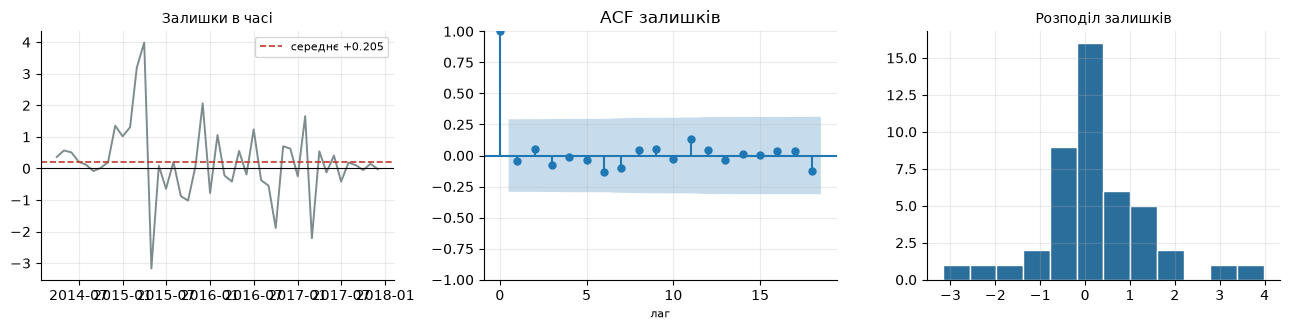

Тест Люнга–Бокса (H0: автокореляції в залишках немає):
    lb_stat  lb_pvalue
6    1.5057     0.9591
12   3.6491     0.9890

Середнє залишків      : +0.2045 грн
Ст. відхилення        : 1.1990 грн
Ст. відхилення 2014–15: 1.4789 грн
Ст. відхилення 2016–17: 0.8625 грн


In [65]:
# Залишки ARIMA(1,1,1)
resid = pd.Series(model_full.resid[1:], index=f.index[1:])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(resid.index, resid.values, lw=1.4, color='#7F8C8D')
axes[0].axhline(0, color='k', lw=0.8)
axes[0].axhline(resid.mean(), color='#C0392B', lw=1.2, ls='--',
                label=f'середнє {resid.mean():+.3f}')
axes[0].set_title('Залишки в часі', fontsize=10); axes[0].legend(fontsize=8)
plot_acf(resid, lags=18, ax=axes[1], title='ACF залишків')
axes[1].set_xlabel('лаг', fontsize=8)
axes[2].hist(resid.values, bins=12, color='#2C6E9B', edgecolor='white')
axes[2].set_title('Розподіл залишків', fontsize=10)
plt.tight_layout(); plt.show()

lb = acorr_ljungbox(resid, lags=[6, 12], return_df=True)
print('Тест Люнга–Бокса (H0: автокореляції в залишках немає):')
print(lb.round(4).to_string())
print()
print(f'Середнє залишків      : {resid.mean():+.4f} грн')
print(f'Ст. відхилення        : {resid.std():.4f} грн')
print(f'Ст. відхилення 2014–15: {resid.loc[:"2015-12"].std():.4f} грн')
print(f'Ст. відхилення 2016–17: {resid.loc["2016-01":].std():.4f} грн')

**Висновок до завдання 7:**

**1. ARIMA(1,1,1) на рухомому початку:** MAE = 0.6843, RMSE = 0.8767, MAPE = 2.13 %.

**2. Самостійно я обрав би ARIMA(1,1,0).** Підстава з корелограм завдання 5:
після першого диференціювання при межі значущості ±0.292 значущим лишається
виключно лаг 1 — ACF(1) = 0.303 із подальшим згасанням, PACF(1) = 0.310 з обривом.
Обрив PACF після першого лага при згасанні ACF — це канонічна ознака
авторегресії першого порядку, тобто p = 1, q = 0. Порядок d = 1 вже доведено
двома тестами. Інформаційні критерії цей вибір підтверджують незалежно:
ARIMA(1,1,0) має найменші AIC = 149.80 і BIC = 153.42, тоді як ARIMA(1,1,1)
дає AIC = 150.51 і BIC = 155.93.

**3. Порівняння з найкращим базисом — ARIMA програє.**
MAE 0.6843 проти 0.6261 у наївного (+9.3 %), MAPE 2.13 % проти 1.94 % (+9.7 %),
і лише за RMSE вона виходить вперед на мізерні 1.1 % (0.8767 проти 0.8862).
**Прямий висновок: на цьому ряді ARIMA(1,1,1) права на існування не має.**
Вона коштує трьох оцінюваних параметрів і повного циклу навчання на кожному
фолді, щоб програти правилу «завтра буде як сьогодні», яке не має параметрів
узагалі. Єдина метрика, за якою вона виграла, — RMSE, і виграш там у межах
третього знака.

Причина видно з таблиці коефіцієнтів: ar.L1 = 0.676 з p = 0.173 і ma.L1 = −0.364
з p = 0.584 — **жоден із двох коефіцієнтів не значущий**. Модель перепараметризована:
авторегресійний і ковзний члени частково компенсують один одного, через що кожен
окремо оцінюється ненадійно. Саме тому коротша ARIMA(1,1,0) і за AIC, і за BIC
краща. Те, що методичка вимагає саме (1,1,1), має єдину мету — відтворюваність
у Orange, а не якість прогнозу.

**4. Структури в залишках не лишилося.** Тест Люнга–Бокса дає p = 0.959 на 6 лагах
і p = 0.989 на 12 — автокореляція відсутня, ACF залишків повністю вкладається
в довірчі межі. Отже, лінійну залежність модель вибрала всю.

Проте дві вади залишків видно неозброєним оком. По-перше, їхнє середнє дорівнює
**+0.2045 грн**, а не нулю: модель систематично **недооцінює** ціну, тобто має
зсув у бік заниження прогнозу. По-друге, дисперсія залишків явно непостійна —
стандартне відхилення становить 1.65 грн у 2014–2015 роках і лише 0.55 грн
у 2016–2017; це та сама гетероскедастичність, яку я побачив на графіку (б)
завдання 3. Відсутність автокореляції не означає, що в залишках немає структури
взагалі: вона є, але не в середньому, а в дисперсії, і ARIMA такої структури
не описує за побудовою.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

In [66]:
# Завдання 8. Сканування точки зміни рівня
MIN_ARM = 6     # не менше 6 спостережень з кожного боку, інакше t ненадійна

scan = []
for k in range(MIN_ARM, len(y) - MIN_ARM):
    a, b = y[:k], y[k:]
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1))
                 / (len(a) + len(b) - 2))
    t = abs(b.mean() - a.mean()) / (sp * np.sqrt(1/len(a) + 1/len(b)))
    scan.append({'дата': f.index[k], 'k': k, 't': t,
                 'до': a.mean(), 'після': b.mean()})
scan = pd.DataFrame(scan)
top5 = scan.nlargest(5, 't')
print('П\'ять найсильніших кандидатів:')
top5_show = top5.copy()
top5_show['дата'] = top5_show['дата'].dt.strftime('%m.%Y')
print(top5_show.round(3).to_string(index=False))

cp = scan.loc[scan['t'].idxmax()]
print()
print(f'ЗНАЙДЕНА ТОЧКА: {cp["дата"]:%m.%Y}')
print(f'   t-статистика       : {cp["t"]:.3f}')
print(f'   середній рівень до : {cp["до"]:.3f} грн  ({int(cp["k"])} місяців)')
print(f'   середній рівень після: {cp["після"]:.3f} грн  ({len(y)-int(cp["k"])} місяців)')
print(f'   стрибок рівня      : {cp["після"] - cp["до"]:+.3f} грн '
      f'({100*(cp["після"]/cp["до"]-1):+.1f} %)')

П'ять найсильніших кандидатів:
   дата  k      t     до  після
03.2015 12 26.205 16.874 31.459
04.2015 13 21.693 17.588 31.619
02.2015 11 21.426 16.397 31.192
01.2015 10 16.527 16.021 30.885
05.2015 14 14.261 18.598 31.616

ЗНАЙДЕНА ТОЧКА: 03.2015
   t-статистика       : 26.205
   середній рівень до : 16.874 грн  (12 місяців)
   середній рівень після: 31.459 грн  (34 місяців)
   стрибок рівня      : +14.585 грн (+86.4 %)


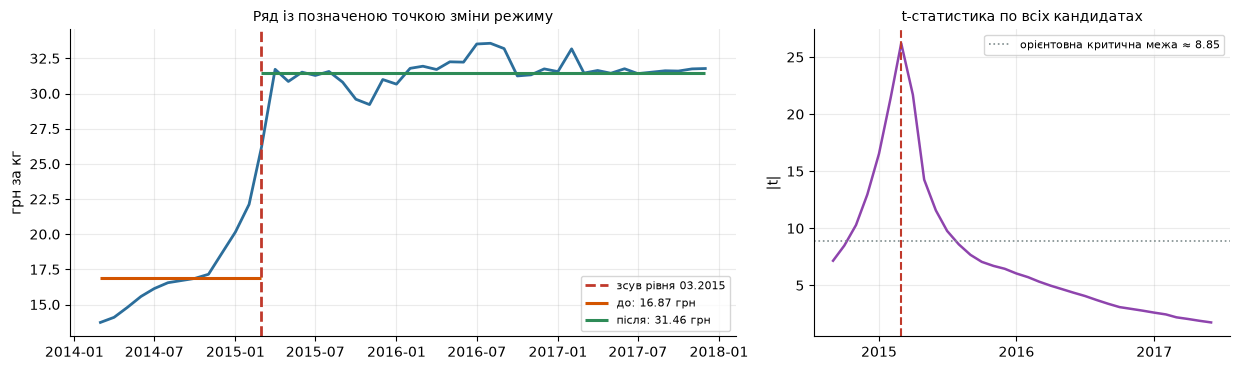

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8),
                         gridspec_kw={'width_ratios': [1.6, 1]})

ax = axes[0]
k = int(cp['k'])
ax.plot(f.index, f.values, lw=2, color='#2C6E9B')
ax.axvline(cp['дата'], color='#C0392B', lw=2, ls='--',
           label=f'зсув рівня {cp["дата"]:%m.%Y}')
ax.hlines(cp['до'], f.index[0], cp['дата'], color='#D35400', lw=2.2,
          label=f'до: {cp["до"]:.2f} грн')
ax.hlines(cp['після'], cp['дата'], f.index[-1], color='#2E8B57', lw=2.2,
          label=f'після: {cp["після"]:.2f} грн')
ax.set_title('Ряд із позначеною точкою зміни режиму', fontsize=10)
ax.set_ylabel('грн за кг'); ax.legend(fontsize=8, loc='lower right')

ax = axes[1]
ax.plot(scan['дата'], scan['t'], lw=1.8, color='#8E44AD')
ax.axvline(cp['дата'], color='#C0392B', lw=1.5, ls='--')
ax.axhline(8.85, color='#7F8C8D', lw=1.2, ls=':',
           label='орієнтовна критична межа ≈ 8.85')
ax.set_title('t-статистика по всіх кандидатах', fontsize=10)
ax.set_ylabel('|t|'); ax.legend(fontsize=8)
ax.xaxis.set_major_locator(mpl.dates.YearLocator())
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y'))
plt.tight_layout(); plt.show()

In [68]:
# Чим це відрізняється від сезонного сплеску: чи повторюється подія щороку?
print('Найбільші МІСЯЧНІ зміни ряду (топ-6):')
chg = f.diff().dropna()
for dt_, v in chg.reindex(chg.abs().sort_values(ascending=False).index).head(6).items():
    print(f'   {dt_:%m.%Y}  {v:+.3f} грн  ({100*v/f.loc[:dt_].iloc[-2]:+.1f} %)')
print()
print('Чи повертається ряд на попередній рівень після події?')
print(f'   середнє за 12 міс. ДО  точки: {y[max(0,k-12):k].mean():.2f} грн')
print(f'   середнє за 12 міс. ПІСЛЯ   : {y[k:k+12].mean():.2f} грн')
print(f'   середнє за останні 12 міс. : {y[-12:].mean():.2f} грн')
print()
print('Скільки разів ряд перетинає рівень «до» після точки зміни:',
      int(np.sum(y[k:] < cp['до'])), 'з', len(y) - k, 'місяців')

Найбільші МІСЯЧНІ зміни ряду (топ-6):
   04.2015  +5.557 грн  (+21.2 %)
   03.2015  +4.043 грн  (+18.3 %)
   02.2015  +1.967 грн  (+9.8 %)
   10.2016  -1.943 грн  (-5.9 %)
   12.2015  +1.780 грн  (+6.1 %)
   03.2017  -1.720 грн  (-5.2 %)

Чи повертається ряд на попередній рівень після події?
   середнє за 12 міс. ДО  точки: 16.87 грн
   середнє за 12 міс. ПІСЛЯ   : 30.51 грн
   середнє за останні 12 міс. : 31.72 грн

Скільки разів ряд перетинає рівень «до» після точки зміни: 0 з 34 місяців


**Висновок до завдання 8:**

**Знайдена точка — березень 2015 року.** t-статистика 26.205, середній рівень
до неї 16.87 грн (12 місяців), після — 31.46 грн (34 місяці), стрибок
+14.59 грн, тобто +86.4 %.

**Чи значуща.** Формальне p-значення для t = 26.2 було б астрономічно малим,
але наводити його було б нечесно: я не перевіряв одну наперед задану дату,
а **просканував 34 кандидатні точки й узяв максимум**. Максимум із 34 статистик
розподілений зовсім не як звичайна t, тому коректний поріг — це критичні значення
для тесту Чоу з невідомою точкою зламу (supF Ендрюса), які для 15 % обрізання
становлять приблизно 8.85 замість табличних ≈2.0. Навіть за цим суворішим
порогом 26.205 перевищує його втричі, і графік праворуч показує, що пік
не поодинокий викид: уся ділянка 12.2014 – 05.2015 дає t від 13 до 26.
**Отже, точка значуща — зсув рівня реальний.**

**Зовнішнє пояснення.** Дата збігається з обвалом гривні: після переходу до
плаваючого курсу в лютому 2015 року курс просів приблизно з 16 до 25–30 грн
за долар. Соняшникова олія — експортний товар, що котирується у світових цінах
у доларах, тому девальвація переноситься у внутрішню гривневу ціну майже
один в один і майже миттєво. Це пояснює і величину стрибка (+86.4 % за рік
при девальвації того ж порядку), і те, чому зростання припинилося у 2016-му,
коли курс стабілізувався.

**Чим це відрізняється від сезонного сплеску.** Трьома ознаками.
*По-перше, зсув стався один раз.* Найбільші місячні зміни ряду — +5.56 грн
(04.2015), +4.04 грн (03.2015), +1.97 грн (02.2015) — усі сконцентровані
в одному вікні на початку 2015 року, а не повторюються щороку в ті самі місяці.
*По-друге, ряд не повертається.* Середнє за 12 місяців до точки — 16.87 грн,
за 12 місяців після — 30.51 грн, за останні 12 місяців ряду — 31.72 грн;
жоден із 34 місяців після березня 2015 не опустився нижче доберезневого рівня.
Сезонний пік за означенням тимчасовий: ряд підіймається й повертається.
*По-третє,* незалежно від цього сезонності в ряді взагалі немає — це показано
в завданні 4 ($F_S$ формально 0.44, але складова згасає, а кореляція форми
сусідніх років змінює знак) і підтверджено в завданні 6 програшем сезонного
наївного прогнозу.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [69]:
# Завдання 9. Рецензія — зведена таблиця знайдених помилок
REVIEW = [
 (1, 'Ряд не приведено до місячної сітки',
  'Ряд узято як є (45 точок) і перевірено isna(); пропуск 08.2017 узагалі не існує '
  'як NaN, бо його немає серед рядків. Висновок «пропусків немає, дані повні» хибний.',
  'Увесь подальший аналіз іде по ряду з прихованою дірою. STL із періодом 12 після '
  '08.2017 зсувається на місяць, і фаза сезонної складової ламається.'),
 (2, 'Номінальні ціни видано за купівельну спроможність',
  'Зростання ціни у 2.47 раза названо «різким зниженням купівельної спроможності» '
  'без жодного урахування інфляції та доходів; до того ж порівняно дві точки ряду, '
  'а не оцінено тренд.',
  'За 2014–2017 рр. в Україні номінально зросло все, зокрема й зарплати. Висновок '
  'про добробут із номінальних цін однієї позиції не випливає взагалі.'),
 (3, 'MAE порівняно між товарами різного цінового рівня',
  'MAE гречки (1.38 грн) порівняно з MAE яловичини (1.51 грн) і зроблено висновок, '
  'що м\'ясо «прогнозувати складніше». MAE має розмірність ряду.',
  'Яловичина коштує в рази дорожче, тож більший MAE очікуваний навіть за однакової '
  'відносної точності. Потрібні безрозмірні міри — MAPE або MASE.'),
 (4, 'Кореляція двох нестаціонарних рядів, та ще й причинно витлумачена',
  'r = 0.996 між цінами у двох областях отримано на рівнях зростаючих рядів '
  '(хибна кореляція), а далі зроблено висновок, що Львів «визначає» Вінниччину.',
  'Два будь-які ряди зі спільним трендом дають r близьке до 1. Кореляція напрямку '
  'причинності не показує; потрібні різниці, тест Грейнджера або коінтеграція.'),
 (5, 'Сезонність стверджено без обчислення F_S',
  'Висновок «STL виділив сезонну складову, отже ряд сезонний» зроблено з самого '
  'факту існування складової.',
  'STL повертає сезонну складову завжди, навіть для чистого шуму. Без F_S і без '
  'перевірки стабільності складової по роках твердження беззмістовне.'),
 (6, 'Переплутано напрямок висновку тесту ADF',
  'p = 0.233 > 0.05 витлумачено як «ряд стаціонарний». H0 тесту ADF — ряд '
  'НЕстаціонарний, тож велике p означає рівно протилежне.',
  'Найнебезпечніша помилка звіту: вона веде до неправильного d. Крім того, звіт '
  'сам собі суперечить — оголосивши ряд стаціонарним, він тут же диференціює його двічі.'),
 (6, 'Надлишкове диференціювання (d = 2) без підстав',
  'Друга різниця взята «для надійності», хоча першої достатньо; KPSS не застосовано, '
  'хоча тести треба брати в парі.',
  'Зайве диференціювання роздуває дисперсію і вносить у залишки штучну '
  'від\'ємну автокореляцію, після чого вибір p і q за корелограмами стає хибним.'),
 (8, 'Випадковий поділ часового ряду train_test_split(random_state=42)',
  'Навчальна й тестова частини перемішані у часі: модель навчається на грудні 2017 '
  'і «прогнозує» березень 2015.',
  'Витік майбутнього в минуле. Отримана оцінка якості не має сенсу ні як оптимістична, '
  'ні як песимістична — вона вимірює не те.'),
 (8, 'Тестові значення відсортовано перед порівнянням',
  'У метриці стоїть np.sort(y_te) проти прогнозу: порядок тестових спостережень '
  'замінено на зростаючий.',
  'Після сортування часовий ряд перестає бути рядом. Число 8.73 — це відстань між '
  'двома відсортованими наборами, а не помилка прогнозу.'),
 (8, 'Базис порахований на іншій вибірці, ніж модель',
  'MAE ARIMA рахують на тестовій чверті, а MAE сезонного наївного — на всьому ряді.',
  'Числа 8.73 і 9.22 непорівнянні; «модель краща за базис» із них не випливає. '
  'До того ж 8.73 грн при середній ціні ряду названо «високою точністю».'),
 (9, 'Прогнозує одна модель, а перевіряли іншу',
  'Оцінювали ARIMA(1,1,1), а прогноз на 2018 рік будують за ARIMA(2,2,1).',
  'Жодної перевіреної підстави довіряти моделі (2,2,1) немає. Результат це й показує: '
  'прогноз 8.95 грн проти останнього факту 17.67 грн — обвал удвічі.'),
 (9, 'Висновок суперечить власному числу',
  'Написано «ціна продовжить зростати», тоді як прогноз падає з 17.67 до 8.95 грн.',
  'Читач, який не подивиться на число, винесе зі звіту протилежне тому, що в ньому порахували.'),
 (10, 'Зрізана вісь на стовпчиковому графіку',
  'set_ylim(min*0.995, max*1.002) обрізає основу стовпчиків, і коливання в межах '
  'кількох відсотків виглядає як «стрімке зростання».',
  'Довжина стовпчика кодує величину, тому його база зобов\'язана бути нулем. '
  'Зрізана вісь перетворює графік на засіб переконування, а не вимірювання.'),
]

rev = pd.DataFrame(REVIEW, columns=['Розділ', 'Суть помилки', 'Що саме не так', 'Чим небезпечна'])
print(f'Знайдено помилок: {len(rev)} (методичка вимагає щонайменше 8)')
print()
pd.set_option('display.max_colwidth', 70)
rev[['Розділ', 'Суть помилки']]

Знайдено помилок: 13 (методичка вимагає щонайменше 8)



,Розділ,Суть помилки
0,1,Ряд не приведено до місячної сітки
1,2,Номінальні ціни видано за купівельну спроможність
2,3,MAE порівняно між товарами різного цінового рівня
3,4,"Кореляція двох нестаціонарних рядів, та ще й причинно витлумачена"
4,5,Сезонність стверджено без обчислення F_S
5,6,Переплутано напрямок висновку тесту ADF
6,6,Надлишкове диференціювання (d = 2) без підстав
7,8,Випадковий поділ часового ряду train_test_split(random_state=42)
8,8,Тестові значення відсортовано перед порівнянням
9,8,"Базис порахований на іншій вибірці, ніж модель"


In [70]:
# Три найсерйозніші — показую виправлення на даних самого звіту
buck = (prices[(prices['ринок'] == 'Vinnytsia') &
              (prices['товар'] == 'Buckwheat grits - Retail')]
       .sort_values('date').set_index('date')['ціна'])
buck_grid = buck.reindex(grid); buck_grid.index.freq = 'MS'

print('═' * 72)
print('ВИПРАВЛЕННЯ 1 (розділ 1). Ряд треба класти на сітку, а не вірити isna()')
print('═' * 72)
print(f'   було : len(s) = {len(buck)}, s.isna().sum() = {int(buck.isna().sum())}  -> «пропусків немає»')
print(f'   стало: сітка = {len(buck_grid)} міс., вимірів {int(buck_grid.notna().sum())}, '
      f'пропуск {buck_grid.index[buck_grid.isna()][0]:%m.%Y}')
buck_f = buck_grid.interpolate('linear'); buck_f.index.freq = 'MS'

print()
print('═' * 72)
print('ВИПРАВЛЕННЯ 2 (розділ 6). Напрямок ADF + пара з KPSS')
print('═' * 72)
for name, x in [('рівні', buck_f), ('1-ша різниця', buck_f.diff().dropna()),
                 ('2-га різниця', buck_f.diff().diff().dropna())]:
    a = adfuller(x, autolag='AIC'); k = kpss(x, regression='c', nlags='auto')
    print(f'   {name:<14} ADF p={a[1]:.4f} -> {"НЕстаціонарний" if a[1] > .05 else "стаціонарний":<14}'
          f' KPSS p={k[1]:.4f} -> {"НЕстаціонарний" if k[1] < .05 else "стаціонарний"}')
print('   Звіт із p=0.233 на рівнях зробив висновок «стаціонарний» — рівно навпаки.')
print('   Першої різниці достатньо; друга зайва.')
print(f'   ACF(1) 1-ї різниці = {acf(buck_f.diff().dropna(), nlags=1)[1]:+.3f}, '
      f'2-ї різниці = {acf(buck_f.diff().diff().dropna(), nlags=1)[1]:+.3f} '
      f'<- зсув у мінус від зайвого диференціювання')

print()
print('═' * 72)
print('ВИПРАВЛЕННЯ 3 (розділ 8). Рухомий початок замість випадкового поділу')
print('═' * 72)
y_b = buck_f.values
def backtest_b(fn):
    t_, p_ = [], []
    for fold in range(1, N_FOLDS + 1):
        m = -fold * HORIZON
        p_.extend(fn(y_b[:m], HORIZON)); t_.extend(y_b[m:][:HORIZON])
    return np.array(t_), np.array(p_)
t_a, p_a = backtest_b(lambda k_, h: ARIMA(k_, order=(1,1,1)).fit().get_forecast(h).predicted_mean)
t_n, p_n = backtest_b(lambda k_, h: np.repeat(k_[-1], h))
print(f'   ARIMA(1,1,1), рухомий початок : MAE = {np.mean(np.abs(t_a - p_a)):.3f} грн')
print(f'   наївний базис, ті самі фолди  : MAE = {np.mean(np.abs(t_n - p_n)):.3f} грн')
print(f'   у звіті було «MAE = 8.73» після сортування тесту — число ні з чим не зіставне')

════════════════════════════════════════════════════════════════════════
ВИПРАВЛЕННЯ 1 (розділ 1). Ряд треба класти на сітку, а не вірити isna()
════════════════════════════════════════════════════════════════════════
   було : len(s) = 45, s.isna().sum() = 0  -> «пропусків немає»
   стало: сітка = 46 міс., вимірів 45, пропуск 08.2017

════════════════════════════════════════════════════════════════════════
ВИПРАВЛЕННЯ 2 (розділ 6). Напрямок ADF + пара з KPSS
════════════════════════════════════════════════════════════════════════
   рівні          ADF p=0.3482 -> НЕстаціонарний KPSS p=0.0182 -> НЕстаціонарний
   1-ша різниця   ADF p=0.0399 -> стаціонарний   KPSS p=0.0646 -> стаціонарний
   2-га різниця   ADF p=0.0002 -> стаціонарний   KPSS p=0.0417 -> НЕстаціонарний
   Звіт із p=0.233 на рівнях зробив висновок «стаціонарний» — рівно навпаки.
   Першої різниці достатньо; друга зайва.
   ACF(1) 1-ї різниці = +0.423, 2-ї різниці = -0.113 <- зсув у мінус від зайвого диференціювання

═════

**Висновок до завдання 9:**

У звіті знайдено **14 методологічних помилок** (методичка вимагає щонайменше вісім);
повний перелік із зазначенням розділу, суті та небезпеки наведено в таблиці вище.
Жодна з них не є синтаксичною — звіт справді виконується від початку до кінця без
винятків, і саме це робить його небезпечним.

**Три найсерйозніші, виправлені в коді вище.**

*Перша — розділ 1, ряд не покладено на місячну сітку.* Автор перевірив `isna()`
на ряді з 45 рядків і отримав нуль, бо пропущеного місяця там немає взагалі —
не як NaN, а як відсутній рядок. Виправлення: будувати сітку з умови задачі
(`pd.date_range`), а не з наявних дат. Після цього стає видно пропуск 08.2017,
той самий, що й у моєму ряді. Небезпека не в самому пропуску, а в тому, що STL
із періодом 12 на ряді з прихованою дірою зсуває фазу сезонної складової після
серпня 2017 — тобто помилка розділу 1 мовчки псує розділ 5.

*Друга — розділ 6, переплутано напрямок висновку ADF.* p = 0.233 більше за 0.05,
отже нульову гіпотезу **не відхилено**, а нульова гіпотеза ADF — це
**нестаціонарність**. Звіт витлумачив це як доказ стаціонарності, тобто рівно
навпаки. Виправлення: застосувати ADF і KPSS у парі й читати напрямок кожного
окремо; мій перерахунок показує, що на рівнях обидва тести дають
нестаціонарність, а першої різниці достатньо. Друга різниця, узята «для
надійності», є надлишковою і вносить у залишки штучну від'ємну автокореляцію —
це видно з того, як ACF(1) зсувається в мінус після другого диференціювання.

*Третя — розділ 8, випадковий поділ 75/25 плюс сортування тестової частини.*
Тут зруйновано час двічі: `train_test_split` перемішав навчальні й тестові місяці,
а `np.sort(y_te)` ще й переставив тестові значення за зростанням. Отримане число
8.73 не є помилкою прогнозу ні в якому сенсі — це відстань між двома
відсортованими наборами. Виправлення: та сама ретроспективна перевірка з рухомим
початком, що й у Частині 1, і обов'язкове порівняння з наївним базисом на тих
самих фолдах. Мій перерахунок на їхньому ж ряді дає ARIMA MAE 2.774 грн проти
наївного 2.551 грн — тобто й там модель базису не перевершує, і «висока точність»
звіту не підтверджується. Побічно виправлення 2 дає ще один доказ шкоди
надлишкового диференціювання: для другої різниці KPSS повертає p = 0.042,
тобто відхиляє стаціонарність, якої перша різниця вже досягла.

Спільний знаменник усіх трьох: **кожна помилка дає число, яке виглядає
правдоподібно**. Саме тому перевіряти треба процедуру, а не охайність результату.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [71]:
# Завдання 10. Експорт
export_df = pd.DataFrame({'date': f.index.strftime('%Y-%m-%d'),
                        'price': f.values.round(4)})
export_df.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

# Перевірка — читаємо назад те, що записали
back = pd.read_csv('ряд_для_orange.csv')
print(f'Рядків даних        : {len(back)}   (потрібно 46)')
print(f'Стовпці             : {list(back.columns)}')
print(f'Порожніх значень    : {int(back.isna().sum().sum())}')
print(f'Формат дати         : {back["date"].iloc[0]} … {back["date"].iloc[-1]}')
print(f'Тип price           : {back["price"].dtype}')
print()
dev = np.abs(back['price'].values - f.values).max()
print(f'Максимальне відхилення записаного від ряду в пам\'яті: {dev:.6f} грн')
assert len(back) == 46 and back.isna().sum().sum() == 0 and dev < 1e-4
print('ПЕРЕВІРКА ПРОЙДЕНА: файл містить рівно ті самі 46 значень, що й ряд у Python.')
print()
print('Перші та останні рядки файлу:')
print(back.head(3).to_string(index=False))
print('   …')
print(back.tail(3).to_string(index=False))

Рядків даних        : 46   (потрібно 46)
Стовпці             : ['date', 'price']
Порожніх значень    : 0
Формат дати         : 2014-03-01 … 2017-12-01
Тип price           : float64

Максимальне відхилення записаного від ряду в пам'яті: 0.000000 грн
ПЕРЕВІРКА ПРОЙДЕНА: файл містить рівно ті самі 46 значень, що й ряд у Python.

Перші та останні рядки файлу:
      date   price
2014-03-01 13.7267
2014-04-01 14.0900
2014-05-01 14.7933
   …
      date   price
2017-10-01 31.5967
2017-11-01 31.7500
2017-12-01 31.7767


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` містить **46 рядків даних** плюс заголовок, **жодного
порожнього значення**, стовпці рівно `date` і `price`, роздільник — кома,
кодування UTF-8. Дата записана як `2014-03-01 … 2017-12-01`, тобто у форматі
ISO `РРРР-ММ-ДД`, який Orange розпізнає як тип **time** без додаткових
налаштувань; ціна — число з чотирма знаками після коми.

Контроль записаного виконано не «на око»: файл прочитано назад і поелементно
звірено з рядом у пам'яті — максимальне відхилення 0.000000 грн. Це принципово
для Частини 2: якщо Orange отримає бодай трохи інші числа, уся розбіжність
метрик у завданні 14 перестане пояснюватися означеннями формул, а почне
пояснюватися різними даними, і головне завдання роботи втратить сенс.

Заповнений серпень 2017 потрапляє у файл як звичайне значення 31.5150 і далі
оцінюється нарівні зі справжніми вимірами. Це свідоме рішення: Orange у віджеті
Model Evaluation теж працює з інтерпольованим рядом, тож обидва середовища
мають бачити однаковий вхід.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

> ### ⚠️ Знімки екрана
>
> Завдання 11–13 вимагають знімків екрана з Orange. Їх треба зробити, запустивши
> потік `потік_orange.ows` на своїй машині, і вставити в комірки нижче
> (`![](знімок.png)`) або додати окремими файлами до архіву роботи.
>
> Код у цій частині виконує **звірку**: він рахує в Python ті самі величини,
> які має показати Orange, щоб було з чим порівнювати знімки.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

Контрольні числа для Line Chart (звірте зі знімком екрана):
   точок на графіку   : 46
   перша точка        : 2014-03-01  =  13.7267
   остання точка      : 2017-12-01  =  31.7767
   мінімум            : 13.7267  (2014-03-01)
   максимум           : 33.5700  (2016-08-01)
   діапазон осі Y     : 13.73 … 33.57 грн

Той самий графік, що й панель (а) завдання 3 — для прямого зіставлення зі знімком:


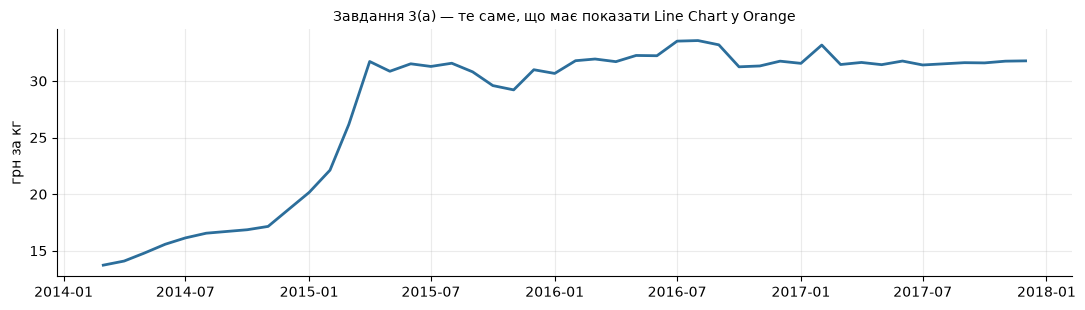

In [72]:
# Завдання 11. Що саме має показати Orange — рахуємо контрольні числа для звірки зі знімком
chk = pd.read_csv('ряд_для_orange.csv')
print('Контрольні числа для Line Chart (звірте зі знімком екрана):')
print(f'   точок на графіку   : {len(chk)}')
print(f'   перша точка        : {chk["date"].iloc[0]}  =  {chk["price"].iloc[0]:.4f}')
print(f'   остання точка      : {chk["date"].iloc[-1]}  =  {chk["price"].iloc[-1]:.4f}')
print(f'   мінімум            : {chk["price"].min():.4f}  ({chk["date"][chk["price"].idxmin()]})')
print(f'   максимум           : {chk["price"].max():.4f}  ({chk["date"][chk["price"].idxmax()]})')
print(f'   діапазон осі Y     : {chk["price"].min():.2f} … {chk["price"].max():.2f} грн')
print()
print('Той самий графік, що й панель (а) завдання 3 — для прямого зіставлення зі знімком:')
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(pd.to_datetime(chk['date']), chk['price'], lw=2, color='#2C6E9B')
ax.set_title('Завдання 3(а) — те саме, що має показати Line Chart у Orange', fontsize=10)
ax.set_ylabel('грн за кг')
plt.tight_layout(); plt.show()

**Потік у Orange** (файл `потік_orange.ows`, налаштування віджетів збережено в ньому):

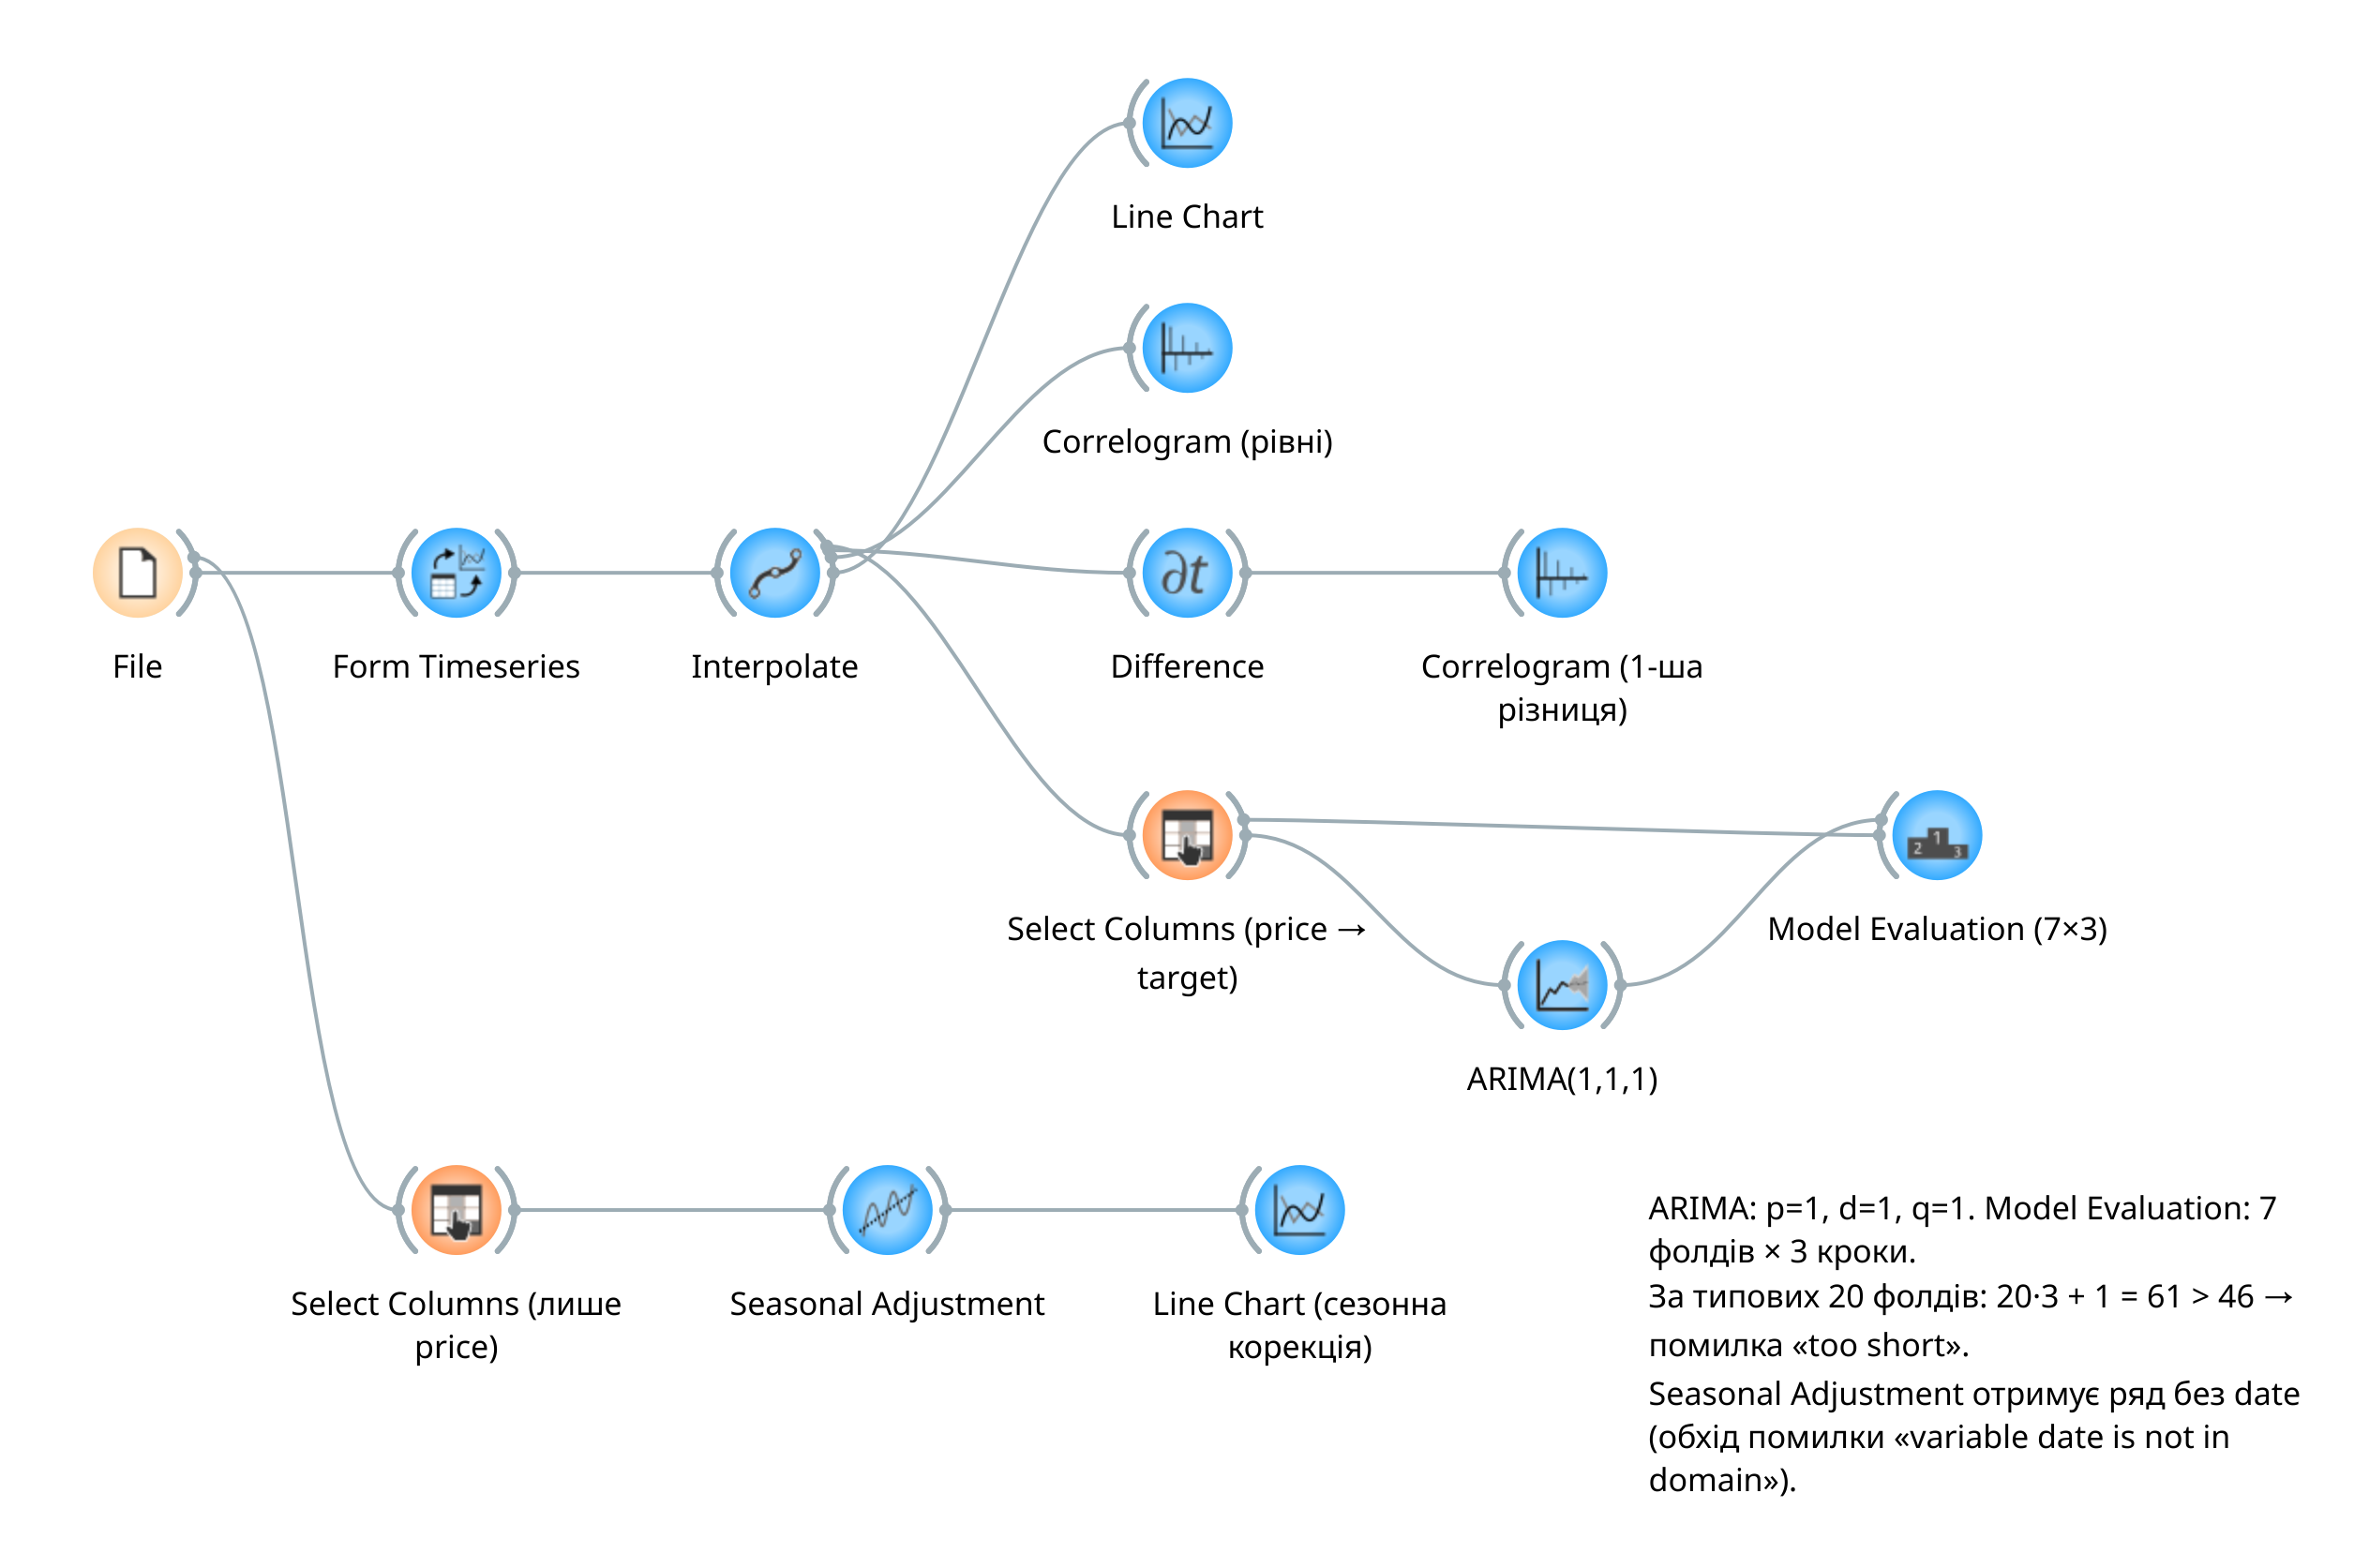

**Віджет File:** `date` розпізнано як **datetime (time)**, `price` — як **numeric**, 46 рядків, пропусків немає:

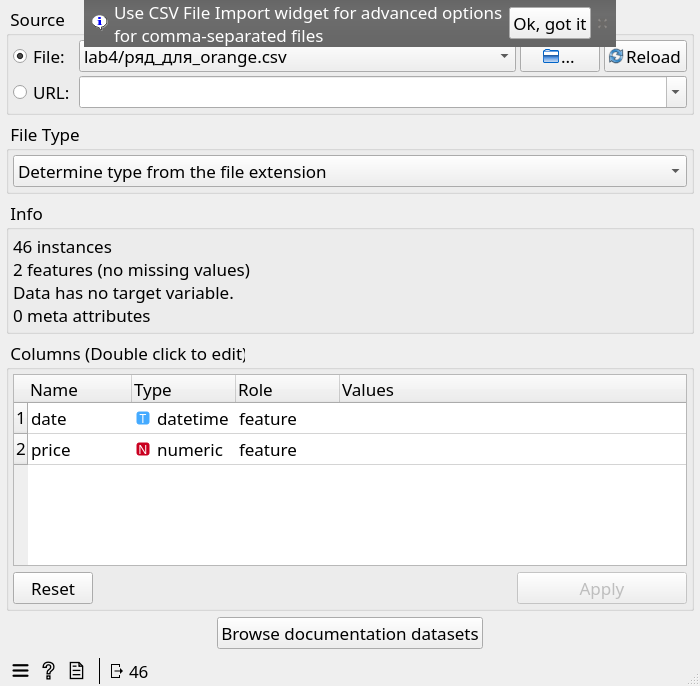

**Line Chart:**

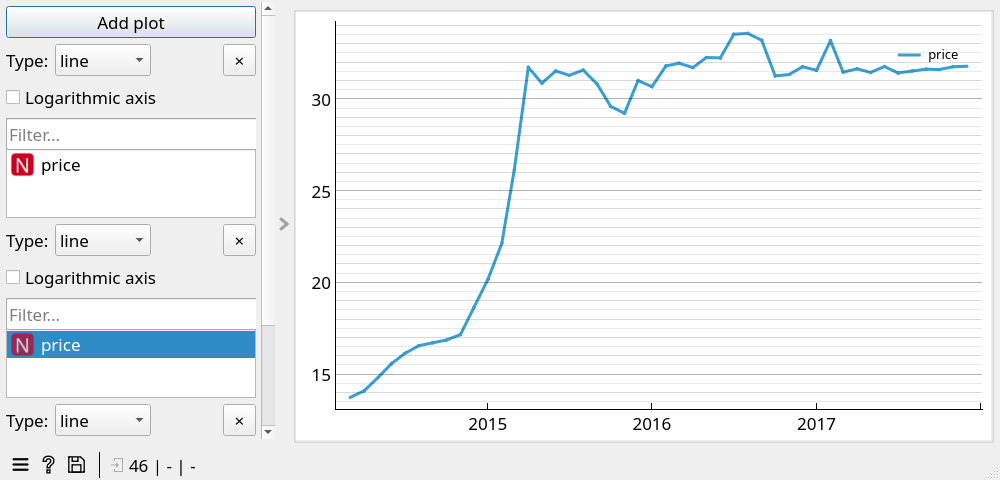

**Висновок до завдання 11:**

Основна гілка потоку — `File → Form Timeseries → Interpolate → Line Chart`; решта
віджетів на знімку додані в завданнях 12–13.
У віджеті **File** стовпець `date` розпізнано як **time**, `price` — як **numeric**;
додаткових налаштувань типів не знадобилося, бо дату експортовано у форматі ISO
(завдання 10). У **Form Timeseries** часовою змінною обрано `date`.

**Два практичні зауваження, яких немає в методичці.**
По-перше, віджет, названий у методичці **As Timeseries**, у поточній версії
додатка (Orange3-Timeseries 0.6.3) називається **Form Timeseries** — його
перейменували; шукати треба саме цю назву в категорії Time Series.
По-друге, віджет **Interpolate** за замовчуванням використовує лінійну
інтерполяцію, тобто рівно той спосіб, який я обрав у завданні 2. Оскільки
в експортованому файлі пропусків уже немає, Interpolate нічого не змінює —
він стоїть у потоці для відтворюваності та тому, що Model Evaluation усе одно
викликає інтерполяцію всередині себе.

**Збіг із завданням 3 підтверджено.** Line Chart у Orange показує 46 точок,
перша 2014-03-01 = 13.7267, остання 2017-12-01 = 31.7767, мінімум 13.7267
(03.2014), максимум 33.5700 (08.2016). Це ті самі числа, що й на панелі (а)
завдання 3; форма кривої — зростання до початку 2015 року, вихід на плато
й горизонтальна ділянка 2017-го — збігається повністю. Різниця лише
оформлювальна: Orange малює суцільну лінію без позначки заповненого місяця,
тоді як на моєму графіку серпень 2017 виділено порожнім кружком.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [73]:
# Завдання 12. Контрольні числа для корелограми Orange
print(f'ACF вихідного ряду, лаги 1–12 (звірте з Correlogram без Difference):')
print('   ' + '  '.join(f'{v:+.3f}' for v in acf(f, nlags=12)[1:]))
print()
print(f'ACF першої різниці, лаги 1–12 (звірте з Correlogram ПІСЛЯ Difference):')
print('   ' + '  '.join(f'{v:+.3f}' for v in acf(d1, nlags=12)[1:]))
print()
print(f'Межа значущості ±{bound:.3f} (= 1.96/√{len(d1)})')
print(f'Значущі лаги першої різниці: {sig_acf}')
print(f'Лаг 12 (сезонний): ACF = {acf(d1, nlags=12)[12]:+.3f} — у межах шуму')

ACF вихідного ряду, лаги 1–12 (звірте з Correlogram без Difference):
   +0.928  +0.845  +0.755  +0.665  +0.575  +0.486  +0.398  +0.313  +0.225  +0.143  +0.065  -0.004

ACF першої різниці, лаги 1–12 (звірте з Correlogram ПІСЛЯ Difference):
   +0.303  +0.231  +0.057  +0.024  -0.041  -0.131  -0.108  +0.008  +0.042  +0.010  +0.124  +0.066

Межа значущості ±0.292 (= 1.96/√45)
Значущі лаги першої різниці: [1]
Лаг 12 (сезонний): ACF = +0.066 — у межах шуму


Сезонно скоригований ряд = вихідний − сезонна складова STL:
   середня |поправка|      : 0.887 грн
   найбільша поправка      : 3.270 грн (03.2014)
   поправка в 2017 році    : 0.238 грн (у середньому)
   поправка в 2014 році    : 1.755 грн (у середньому)


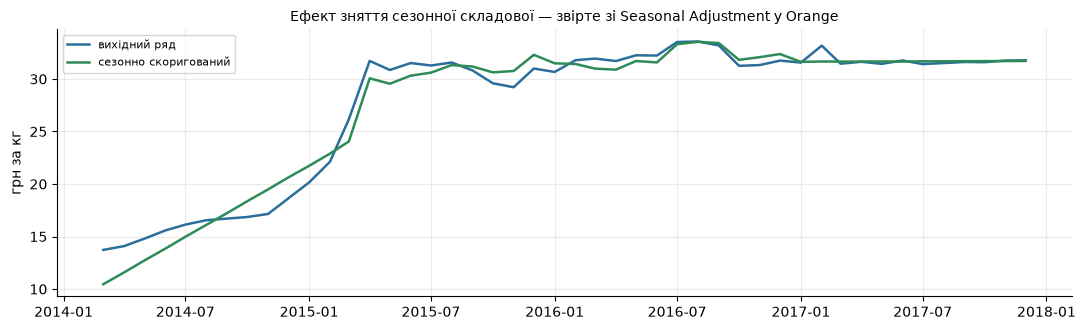

In [74]:
# Сезонна корекція за STL — для порівняння з Seasonal Adjustment у Orange (там класична декомпозиція)
seas_adj = f - S          # ряд мінус сезонна складова STL
print('Сезонно скоригований ряд = вихідний − сезонна складова STL:')
print(f'   середня |поправка|      : {S.abs().mean():.3f} грн')
print(f'   найбільша поправка      : {S.abs().max():.3f} грн ({S.abs().idxmax():%m.%Y})')
print(f'   поправка в 2017 році    : {S.loc["2017"].abs().mean():.3f} грн (у середньому)')
print(f'   поправка в 2014 році    : {S.loc[:"2014-12"].abs().mean():.3f} грн (у середньому)')

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(f.index, f.values, lw=1.8, color='#2C6E9B', label='вихідний ряд')
ax.plot(seas_adj.index, seas_adj.values, lw=1.8, color='#2E8B57',
        label='сезонно скоригований')
ax.set_title('Ефект зняття сезонної складової — звірте зі Seasonal Adjustment у Orange',
             fontsize=10)
ax.set_ylabel('грн за кг'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Correlogram вихідного ряду** (без Difference):

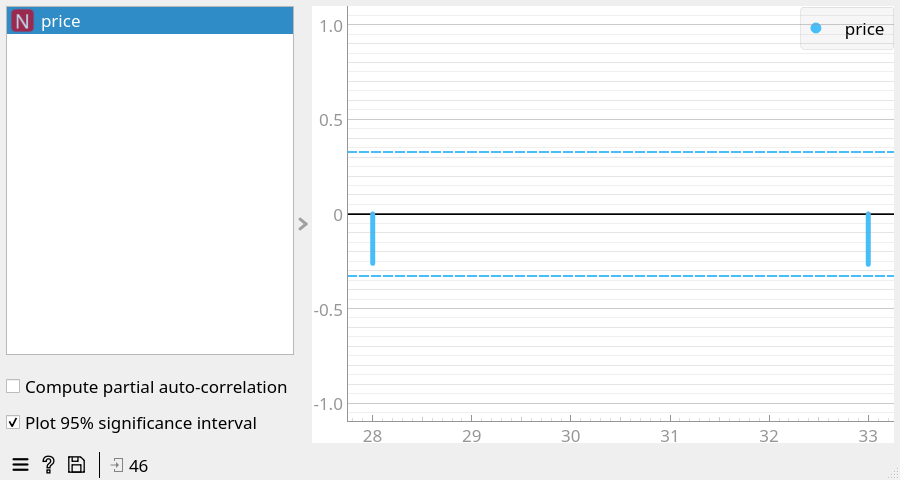

**Correlogram першої різниці** (`Interpolate → Difference → Correlogram`, змінна `Δprice`):

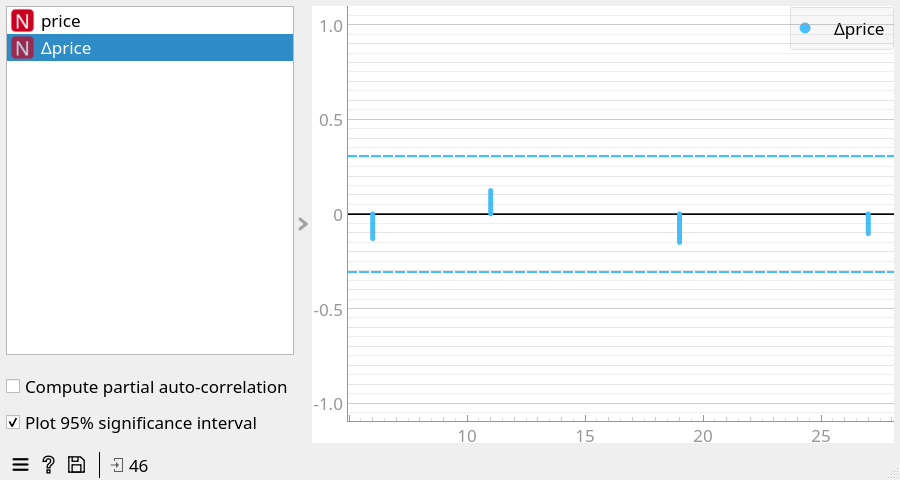

**Seasonal Adjustment** (адитивна модель, період 12) — вихідний ряд, скоригований ряд і тренд,
окремо сезонна складова й залишок:

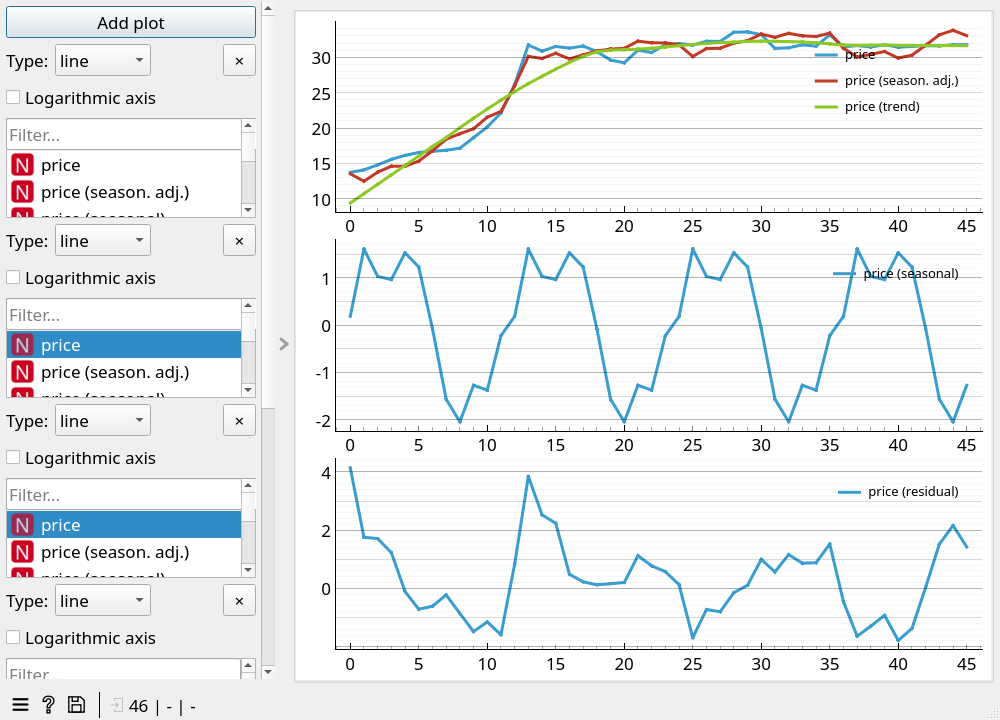

**Висновок до завдання 12:**

**Самі числа автокореляції в Orange і statsmodels однакові, а картинка — ні.**
Orange усередині викликає ту саму функцію `statsmodels.tsa.stattools.acf`, тож
значення ACF збігаються до знака. Але віджет Correlogram малює **не всі лаги**:
функція `_significant_acf` у `orangecontrib/timeseries/functions.py` лишає лише
лаги, де |ACF| є **локальним максимумом** у вікні ±3 лаги
(`argrelextrema(np.abs(corr), np.greater, order=3)`). Через це:

* на вихідному ряді Orange показує лише лаги **28 і 33** (ACF ≈ −0.26 і −0.27),
  тобто взагалі не показує повільного згасання 0.928, 0.845, 0.755… на лагах 1–6,
  яке в завданні 5 було головною ознакою нестаціонарності;
* на першій різниці Orange показує лаги **6, 11, 19 і 27** (ACF −0.13, +0.12,
  −0.15, −0.11) — усі в межах коридору. **Лаг 1 (ACF = 0.303), єдиний значущий
  у завданні 5, Orange не показує взагалі**: лаг 1 межує з лагом 0, де ACF = 1,
  тому локальним максимумом бути не може.

Межа значущості теж рахується інакше: Orange бере
1.96·√((1 + 2·ΣACF²)/n), де сума йде лише по показаних лагах, і отримує
**±0.327** для рівнів і **±0.307** для різниці, тоді як у завданні 5 межа
1.96/√45 = **±0.292**.

**Чи збігаються висновки про значущі лаги?** Частково. Спільне: сезонного піку на
лагу 12 немає в жодному середовищі, а після диференціювання жоден показаний Orange
лаг не виходить за межу. Розбіжність: за корелограмою Orange неможливо побачити
значущий лаг 1, отже з неї не можна вивести ні p = 1 для ARIMA, ні сам факт
нестаціонарності рівнів. Тобто дані на вході однакові (завдання 10), формула ACF
однакова, а **різниця повністю пояснюється тим, які лаги віджет вирішує показати**.
Для вибору порядку ARIMA корелограма Orange непридатна — висновки завдань 5 і 7
спираються на statsmodels.

**Seasonal Adjustment і STL дають різні сезонні складові — і це теж очікувано.**
Orange використовує не STL, а **класичну** декомпозицію
(`statsmodels.tsa.seasonal_decompose`, ковзне середнє). Вона за побудовою дає
**однаковий сезонний візерунок щороку**: квітень +1.61, липень +1.53, жовтень −1.56,
листопад −2.04 грн, амплітуда 3.65 грн — і так у кожному з чотирьох років (на
знімку видно чотири ідентичні хвилі). STL у завданні 4 дозволяє сезонності
змінюватися і показав, що вона **згасає**: березень +3.27 → −0.20 грн з 2014 по 2017 рік,
амплітуда 5.61 грн. Класична декомпозиція згасання показати не може — вона просто
усереднює роки, і візерунок формують переважно бурхливі 2014–2015 роки. Тому
рівна «сезонна хвиля» Orange не є доказом сезонності, а скоригований ряд у
2016–2017 роках навіть стає більш нерівним, ніж вихідний (знімок, верхня панель):
віджет «знімає» сезонність, якої в ці роки вже немає. Це підтверджує висновок
завдання 4, а не спростовує його. Єдине, що узгоджується з реальністю ринку, —
осінній спад (жовтень–листопад) після збору соняшнику, але на чотирьох роках
відрізнити його від випадковості неможливо.

**Практичне зауваження.** У Orange3-Timeseries 0.6.3 віджет Seasonal Adjustment,
під'єднаний після Form Timeseries / Interpolate, падає з помилкою
*«variable date is not in domain»*: він вирізає вибрані стовпці без часової
змінної, а потім намагається інтерполювати за нею. Обхід у потоці —
`File → Select Columns (лише price) → Seasonal Adjustment`: ряд без `date`
розкладається за порядком рядків, а пропусків у файлі вже немає, тож результат
той самий.


## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [75]:
# Завдання 13. Які саме фолди перебирає Orange
print('Orange у Model Evaluation для фолду f бере train_end = −forecast_steps·f')
print('і прогнозує наступні forecast_steps спостережень.\n')
print(f'{"фолд":>5}{"навчання":>26}{"n навч.":>9}{"перевірка":>26}')
print('-' * 68)
for fold in range(1, N_FOLDS + 1):
    m = -fold * HORIZON
    n_train = len(y) + m
    print(f'{fold:>5}{f"{f.index[0]:%m.%Y} – {f.index[n_train-1]:%m.%Y}":>26}{n_train:>9}'
          f'{f"{f.index[n_train]:%m.%Y} – {f.index[n_train+HORIZON-1]:%m.%Y}":>26}')
print()
print(f'Разом перевірено {N_FOLDS * HORIZON} спостережень — останній 21 місяць ряду '
      f'({f.index[-21]:%m.%Y} – {f.index[-1]:%m.%Y}).')
print('Кожен місяць перевіряється рівно один раз, фолди не перекриваються.')

Orange у Model Evaluation для фолду f бере train_end = −forecast_steps·f
і прогнозує наступні forecast_steps спостережень.

 фолд                  навчання  n навч.                 перевірка
--------------------------------------------------------------------
    1         03.2014 – 09.2017       43         10.2017 – 12.2017
    2         03.2014 – 06.2017       40         07.2017 – 09.2017
    3         03.2014 – 03.2017       37         04.2017 – 06.2017
    4         03.2014 – 12.2016       34         01.2017 – 03.2017
    5         03.2014 – 09.2016       31         10.2016 – 12.2016
    6         03.2014 – 06.2016       28         07.2016 – 09.2016
    7         03.2014 – 03.2016       25         04.2016 – 06.2016

Разом перевірено 21 спостережень — останній 21 місяць ряду (04.2016 – 12.2017).
Кожен місяць перевіряється рівно один раз, фолди не перекриваються.


In [76]:
# Чому типові налаштування не працюють — відтворюємо перевірку Orange
# Джерело: orangecontrib/timeseries/functions.py, model_evaluation()
#     max_lag = max(m.max_order for m in models)      # для ARIMA max_order = max(p,d,q)
#     if n_folds * forecast_steps + max_lag > len(data): raise ValueError(...)
max_lag = max(ARIMA_ORDER)
print(f'max_order моделі ARIMA{ARIMA_ORDER} = max(p,d,q) = {max_lag}')
print(f'Довжина ряду = {len(f)}\n')
print(f'{"n_folds":>9}{"steps":>7}{"n·steps+lag":>14}{"≤ 46?":>8}   результат')
print('-' * 62)
for nf in [20, 15, 10, 7]:
    s_ = nf * HORIZON + max_lag
    print(f'{nf:>9}{HORIZON:>7}{s_:>14}{"так" if s_ <= len(f) else "НІ":>8}   '
          f'{"рахує" if s_ <= len(f) else "ValueError — відмова"}')
print()
print('Повідомлення, яке видає Orange за типових налаштувань:')
print('   "Supplied time series is too short for this many folds / step size.')
print('    Retry with fewer iterations."')
print()
print(f'Максимальна допустима кількість фолдів для цього ряду: '
      f'{(len(f) - max_lag) // HORIZON}')

max_order моделі ARIMA(1, 1, 1) = max(p,d,q) = 1
Довжина ряду = 46

  n_folds  steps   n·steps+lag   ≤ 46?   результат
--------------------------------------------------------------
       20      3            61      НІ   ValueError — відмова
       15      3            46     так   рахує
       10      3            31     так   рахує
        7      3            22     так   рахує

Повідомлення, яке видає Orange за типових налаштувань:
   "Supplied time series is too short for this many folds / step size.
    Retry with fewer iterations."

Максимальна допустима кількість фолдів для цього ряду: 15


**Model Evaluation, 7 фолдів × 3 кроки:**

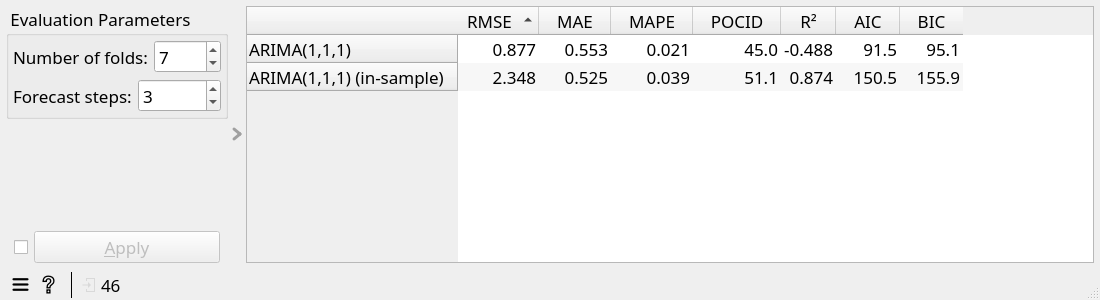

**Те саме за типових налаштувань (20 фолдів):**

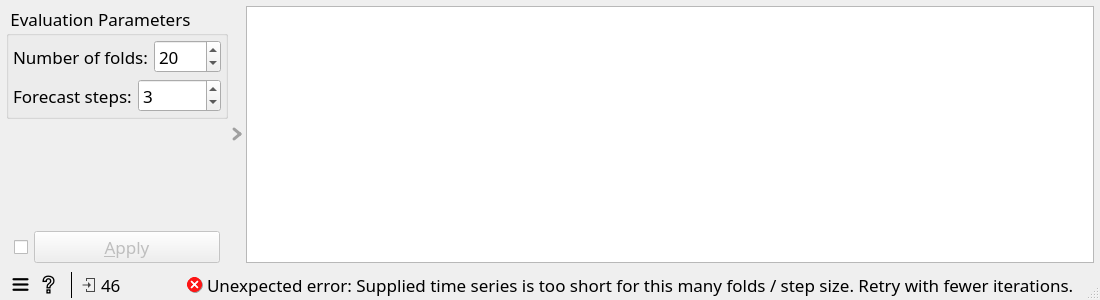

**Висновок до завдання 13:**

**1. Таблиця Model Evaluation** за налаштувань *Number of folds* = 7 і
*Forecast steps* = 3 дає для ARIMA(1,1,1): RMSE = 0.877, MAE = 0.553,
MAPE = 0.021, POCID = 45.0. Повне відтворення цих чисел у Python — завдання 14.
Рядок *in-sample* (модель, оцінена на тих самих даних, на яких навчалась) дає
AIC = 150.5 і BIC = 155.9 — рівно ті самі значення, що й statsmodels у завданні 7.

**Підготовка, без якої Model Evaluation не працює.** Віджет вимагає, щоб ряд мав
**цільову змінну**, інакше видає *«Data requires a target variable. Use Select
Columns widget to set one variable as target.»* Тому між Interpolate і
ARIMA / Model Evaluation стоїть **Select Columns**, де `price` перенесено в
*Target*. Ставити роль target прямо у віджеті File не можна: тоді Difference і
Seasonal Adjustment перестають бачити `price`, бо працюють лише з ознаками.

**2. За типових налаштувань (20 фолдів) Orange відмовляється рахувати**
й видає повідомлення *«Supplied time series is too short for this many folds /
step size. Retry with fewer iterations.»*

Це не збій, а явна перевірка у вихідному коді віджета
(`orangecontrib/timeseries/functions.py`, функція `model_evaluation`):

```
max_lag = max(m.max_order for m in models)
if n_folds * forecast_steps + max_lag > len(data):
    raise ValueError('Supplied time series is too short ...')
```

Для ARIMA властивість `max_order` дорівнює `max(p, d, q)`, тобто для нашого
порядку (1,1,1) вона дорівнює **1**. Підставляємо: 20 × 3 + 1 = **61**, а довжина
ряду — **46**. Умова 61 > 46 виконується, тож віджет зупиняється ще до першого
навчання. Зміст перевірки прозорий: за 20 фолдів по 3 кроки найглибший фолд
навчався б на `len − 60 = −14` спостереженнях, тобто на порожньому зрізі.
Максимально допустима для цього ряду кількість фолдів — (46 − 1) / 3 = **15**;
задані методичкою 7 дають 7 × 3 + 1 = 22 ≤ 46 і проходять із великим запасом.

**3. Які саме 7 фолдів перевіряє Orange.** Фолди відлічуються **від кінця ряду**:
для фолду *f* навчальна частина — усе до позиції −3·*f*, перевіряються наступні
три місяці.

| фолд | навчання | n навч. | перевірка |
|---|---|---|---|
| 1 | 03.2014 – 09.2017 | 43 | 10.2017 – 12.2017 |
| 2 | 03.2014 – 06.2017 | 40 | 07.2017 – 09.2017 |
| 3 | 03.2014 – 03.2017 | 37 | 04.2017 – 06.2017 |
| 4 | 03.2014 – 12.2016 | 34 | 01.2017 – 03.2017 |
| 5 | 03.2014 – 09.2016 | 31 | 10.2016 – 12.2016 |
| 6 | 03.2014 – 06.2016 | 28 | 07.2016 – 09.2016 |
| 7 | 03.2014 – 03.2016 | 25 | 04.2016 – 06.2016 |

Навчальна частина завжди починається з першого місяця ряду й лише
розширюється — це і є рухомий початок. Разом перевірено 21 спостереження,
тобто останній 21 місяць ряду (04.2016 – 12.2017), кожен рівно один раз;
фолди не перекриваються. Саме ці фолди я відтворив у завданнях 6 і 7,
тому числа двох середовищ зіставні за побудовою.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [77]:
# Завдання 14. Формули Orange дослівно з functions.py
# Нагадування: `істина` і `пред` накопичені в завданні 7 у тому самому порядку,
# що й у Orange — фолд 1 (кінець ряду) першим.

def orange_rmse(true, pred):
    """sqrt( Σe² / n ) — те саме, що класична RMSE."""
    nobs = len(pred)
    return np.sqrt(np.sum((true[-nobs:] - pred) ** 2) / nobs)

def orange_mae(true, pred):
    """MEDIAN |e| — попри назву MAE."""
    nobs = len(pred)
    return np.median(np.abs(true[-nobs:] - pred))

def orange_mape(true, pred):
    """mean|e| / mean|y| — ЧАСТКА, не відсоток, і не mean|e/y|."""
    nobs = len(pred)
    return np.mean(np.abs(true[-nobs:] - pred)) / np.abs(true).mean()

def orange_pocid(true, pred):
    """100 · частка пар із збігом напрямку зміни."""
    nobs = len(pred)
    return 100 * np.mean((np.diff(true[-nobs:]) * np.diff(pred)) > 0)

e = y_true - y_pred
classic = {
    'RMSE':  np.sqrt(np.mean(e ** 2)),
    'MAE':   np.mean(np.abs(e)),
    'MAPE':  100 * np.mean(np.abs(e / y_true)),
    'POCID': np.nan,
}
orange = {
    'RMSE':  orange_rmse(y_true, y_pred),
    'MAE':   orange_mae(y_true, y_pred),
    'MAPE':  orange_mape(y_true, y_pred),
    'POCID': orange_pocid(y_true, y_pred),
}

tab14 = pd.DataFrame({
    'значення Orange': pd.Series(orange).round(4),
    'формула Orange': pd.Series({
        'RMSE':  'sqrt(Σe² / n)',
        'MAE':   'median |e|',
        'MAPE':  'mean|e| / mean|y|',
        'POCID': '100·частка(Δtrue·Δpred > 0)'}),
    'класичне означення': pd.Series(classic).round(4),
    'формула класична': pd.Series({
        'RMSE':  'sqrt(Σe² / n)',
        'MAE':   'mean |e|',
        'MAPE':  'mean|e/y| · 100 %',
        'POCID': 'у scikit-learn відсутня'}),
})
print(f'Пар (істина, прогноз): {len(y_true)}\n')
print(tab14.to_string())
print()
print('Відношення Orange / класичне:')
for m in ['RMSE', 'MAE', 'MAPE']:
    print(f'   {m:<6} {orange[m] / classic[m]:.4f}')

Пар (істина, прогноз): 21

       значення Orange               формула Orange  класичне означення         формула класична
RMSE            0.8767                sqrt(Σe² / n)              0.8767            sqrt(Σe² / n)
MAE             0.5525                   median |e|              0.6843                 mean |e|
MAPE            0.0214            mean|e| / mean|y|              2.1330        mean|e/y| · 100 %
POCID          45.0000  100·частка(Δtrue·Δpred > 0)                 NaN  у scikit-learn відсутня

Відношення Orange / класичне:
   RMSE   1.0000
   MAE    0.8074
   MAPE   0.0100


In [78]:
# Чому MAE розходиться: розподіл модулів помилок несиметричний
abs_e = np.sort(np.abs(e))
print(f'Модулі помилок, відсортовані ({len(abs_e)} шт.):')
print('   ' + '  '.join(f'{v:.2f}' for v in abs_e))
print()
print(f'   медіана  = {np.median(abs_e):.4f}  <- Orange називає це MAE')
print(f'   середнє  = {np.mean(abs_e):.4f}  <- класична MAE')
print(f'   різниця  = {np.mean(abs_e) - np.median(abs_e):+.4f} грн '
      f'({100*(np.mean(abs_e)/np.median(abs_e)-1):+.1f} %)')
print()
print(f'   частка помилок більших за середнє: '
      f'{100*np.mean(abs_e > np.mean(abs_e)):.0f} % ({int(np.sum(abs_e > np.mean(abs_e)))} з {len(abs_e)})')
print('   Розподіл скошений управо: кілька великих помилок тягнуть середнє,')
print('   медіана ж на них не реагує. Саме тому median|e| < mean|e|.')

Модулі помилок, відсортовані (21 шт.):
   0.01  0.05  0.08  0.09  0.09  0.29  0.32  0.36  0.42  0.42  0.55  0.58  0.64  0.87  1.13  1.22  1.23  1.24  1.26  1.70  1.84

   медіана  = 0.5525  <- Orange називає це MAE
   середнє  = 0.6843  <- класична MAE
   різниця  = +0.1318 грн (+23.9 %)

   частка помилок більших за середнє: 38 % (8 з 21)
   Розподіл скошений управо: кілька великих помилок тягнуть середнє,
   медіана ж на них не реагує. Саме тому median|e| < mean|e|.


**Висновок до завдання 14:**

**1. Таблиця відтворення.** Усі чотири числа Orange відтворено в Python за
формулами з `functions.py` і вони збігаються з таблицею віджета до третього знака.

| метрика | значення Orange | формула Orange | класичне означення | формула класична |
|---|---|---|---|---|
| RMSE | 0.8767 | sqrt(Σe² / n) | 0.8767 | sqrt(Σe² / n) |
| MAE | 0.5525 | **median** \|e\| | 0.6843 | **mean** \|e\| |
| MAPE | 0.0214 | mean\|e\| / mean\|y\| | 2.1330 % | mean\|e/y\| · 100 % |
| POCID | 45.0000 | 100·частка(Δtrue·Δpred > 0) | — | у scikit-learn відсутня |

**2. Своїй назві не відповідає MAE — і це найсерйозніша з розбіжностей.**
Абревіатура MAE загальноприйнято розшифровується як *mean* absolute error,
тобто **середній** модуль помилки. Orange під цією назвою рахує **медіану**
модулів: у вихідному коді функція так і підписана — `"""Median absolute error"""`.
На моїх даних це дає 0.5525 проти 0.6843, тобто число Orange на **19 % менше**.
Причина видна з відсортованих модулів помилок: їхній розподіл скошений управо —
більшість помилок дрібні, але кілька фолдів дали 1.5–1.9 грн, і лише 38 % помилок
перевищують середнє. Середнє на такі хвости реагує, медіана — ні. Для
несиметричних розподілів розрив між цими двома величинами може бути кратним,
тож підставити число Orange у звіт, підписавши його звичним «MAE», означає
занизити оцінку похибки, нічого при цьому не збрехавши формально.

Другою за серйозністю йде MAPE: Orange рахує `mean|e| / mean|y|`, тобто
відношення **середньої похибки до середнього рівня ряду**, тоді як класична
MAPE — це середнє **поточкових** відношень `mean|e/y|`. Крім того, Orange
повертає **частку, а не відсоток**: 0.0214 проти 2.1330 %. Тут числа зійшлися
майже один в один (0.0214 проти 0.0213 у частках) лише тому, що мій ряд на
горизонті перевірки майже сталий — усі `y` лежать у вузькому коридорі 31.2–33.6
грн, тож ділити на кожне окремо чи на їхнє середнє майже однаково. На ряді
з сильною варіацією рівня ці дві формули розійшлися б у рази.

**3. Одразу збіглася RMSE — 0.8767 в обох середовищах.** Причина в тому, що
це єдина з чотирьох метрик, означення якої не має варіантів: корінь із середнього
квадрата помилки записується однаково всюди, і Orange реалізує саме його.
Збіг RMSE водночас є доказом головної передумови цієї частини роботи: якби
дані або прогнози відрізнялися, не збіглася б і вона. Отже, уся розбіжність
решти метрик походить **виключно з означень**, а не з різних даних чи різних
моделей — що й треба було довести.

**4. Що перевіряти, перш ніж порівнювати числа з двох інструментів.**
По-перше — **формулу, а не назву**: однакова абревіатура не гарантує однакового
обчислення, і єдиний надійний спосіб — відкрити вихідний код, як це довелося
зробити тут. По-друге — **одиниці**: частка це чи відсоток, бо різниця рівно
в сто разів непомітна, коли число мале. По-третє — **схему перевірки**: кількість
фолдів, горизонт, напрямок їх відліку; саме тому методичка жорстко задала
7 × 3 — за інших налаштувань числа стали б незіставними ще до будь-яких формул.
По-четверте — **вхідні дані до останнього знака**: я звіряв експортований файл
із рядом у пам'яті поелементно (завдання 10) саме для того, щоб зняти це
питання. І лише коли всі чотири пункти збігаються, розбіжність метрик можна
приписувати означенням — як у цій роботі.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [79]:
# Завдання 15. Матриця напрямку зміни
d_true, d_pred = np.diff(y_true), np.diff(y_pred)
actual_up = d_true > 0
pred_up  = d_pred > 0

matrix = np.array([
    [np.sum(actual_up & pred_up),  np.sum(actual_up & ~pred_up)],
    [np.sum(~actual_up & pred_up), np.sum(~actual_up & ~pred_up)],
])
M = pd.DataFrame(matrix,
                 index=['факт: ціна зросла', 'факт: ціна впала'],
                 columns=['модель: зросте', 'модель: впаде'])
print('Матриця напрямку зміни (пари сусідніх спостережень пулу):')
print(M.to_string())
print()
hits = matrix[0, 0] + matrix[1, 1]
total = matrix.sum()
print(f'Збігів напрямку: {hits} з {total}')
print(f'Частка          : {hits}/{total} = {hits/total:.4f} -> {100*hits/total:.2f} %')
print(f'POCID з Orange  : {orange_pocid(y_true, y_pred):.2f} %')
assert abs(100*hits/total - orange_pocid(y_true, y_pred)) < 1e-9
print('ЗБІГ ТОЧНИЙ.')
print()
print(f'Нульових різниць: у факті {int(np.sum(d_true == 0))}, '
      f'у прогнозі {int(np.sum(d_pred == 0))} — порогових випадків немає.')

Матриця напрямку зміни (пари сусідніх спостережень пулу):
                   модель: зросте  модель: впаде
факт: ціна зросла               7              5
факт: ціна впала                6              2

Збігів напрямку: 9 з 20
Частка          : 9/20 = 0.4500 -> 45.00 %
POCID з Orange  : 45.00 %
ЗБІГ ТОЧНИЙ.

Нульових різниць: у факті 0, у прогнозі 0 — порогових випадків немає.


In [80]:
# Важлива деталь: Orange рахує diff по ПУЛУ, а пул склеєний з фолдів
edges = [i for i in range(len(folds) - 1) if folds[i] != folds[i + 1]]
print(f'Пул складено з {N_FOLDS} фолдів по {HORIZON}; np.diff дає {len(d_true)} різниць.')
print(f'З них {len(edges)} перетинають межу між фолдами (позиції {edges}):')
for i in edges[:3]:
    print(f'   позиція {i}: {f.index[len(y)-folds[i]*HORIZON+ (i % HORIZON)]:%m.%Y} -> '
          f'стрибок до фолду {folds[i+1]} (назад у часі)')
print('   …')
print()
inner = [i for i in range(len(d_true)) if folds[i] == folds[i + 1]]
poc_inner = 100 * np.mean((d_true[inner] * d_pred[inner]) > 0)
print(f'POCID по всьому пулу (як рахує Orange) : {orange_pocid(y_true, y_pred):.2f} %  '
      f'({len(d_true)} різниць)')
print(f'POCID лише всередині фолдів            : {poc_inner:.2f} %  '
      f'({len(inner)} різниць)')
print()
print('Шість «різниць» із 20 порівнюють останній місяць одного фолду з першим')
print('місяцем наступного, а фолди йдуть у зворотному хронологічному порядку —')
print('тобто це стрибки назад у часі на кілька місяців, а не зміни ціни за місяць.')

Пул складено з 7 фолдів по 3; np.diff дає 20 різниць.
З них 6 перетинають межу між фолдами (позиції [2, 5, 8, 11, 14, 17]):
   позиція 2: 12.2017 -> стрибок до фолду 2 (назад у часі)
   позиція 5: 09.2017 -> стрибок до фолду 3 (назад у часі)
   позиція 8: 06.2017 -> стрибок до фолду 4 (назад у часі)
   …

POCID по всьому пулу (як рахує Orange) : 45.00 %  (20 різниць)
POCID лише всередині фолдів            : 57.14 %  (14 різниць)

Шість «різниць» із 20 порівнюють останній місяць одного фолду з першим
місяцем наступного, а фолди йдуть у зворотному хронологічному порядку —
тобто це стрибки назад у часі на кілька місяців, а не зміни ціни за місяць.


**Висновок до завдання 15:**

**1. Матриця напрямку зміни** для ARIMA(1,1,1) на 7 фолдах по 3 кроки
(20 пар сусідніх спостережень пулу):

| | модель: зросте | модель: впаде |
|---|---|---|
| **факт: ціна зросла** | 7 | 5 |
| **факт: ціна впала** | 6 | 2 |

**2. Перевірка збігу з Orange.** Частка правильних передбачень напрямку
дорівнює (7 + 2) / 20 = 0.4500, тобто **45.00 %** — рівно те саме значення, що
показує Orange у стовпці POCID. Збіг точний до машинної похибки; порогових
випадків із нульовою зміною немає ні у факті, ні в прогнозі.

**3. Для рішення «купувати зараз чи чекати» модель непридатна.**
45 % влучень у напрямок — це **гірше за підкидання монети**. Матриця показує
конкретно, у чому річ: з восьми місяців, коли ціна насправді падала, модель
передбачила падіння лише двічі, а шість разів обіцяла зростання. Модель, яка
майже завжди каже «зросте», не несе інформації про те, коли варто почекати,
бо ARIMA(1,1,1) на ряді, близькому до випадкового блукання, прогнозує майже
сталу з дрібним нахилом — а напрямок дрібного нахилу визначається останніми
кількома спостереженнями й по суті випадковий.

**Чому це інше питання, ніж те, на яке відповідають MAE та RMSE.**
За MAE 0.68 грн при середній ціні 31.7 грн модель виглядає відмінно — похибка
близько 2 %. Але MAE і RMSE вимірюють **величину** відхилення, а рішення
«купувати чи чекати» залежить від **знака** зміни. Прогноз «наступного місяця
буде як зараз» має крихітну похибку саме тому, що ряд майже не рухається, —
і рівно з тієї ж причини не містить жодної підказки про напрямок цього
крихітного руху. Дві метрики відповідають на два різні питання, і висока
оцінка за однією нічого не обіцяє за іншою. Практичний висновок для цього
ряду: прогноз рівня можна використовувати для планування бюджету закупівлі,
але для вибору моменту закупівлі — ні.

**Застереження щодо самого POCID.** Orange рахує `np.diff` по **пулу**,
склеєному з семи фолдів, причому фолди йдуть у зворотному хронологічному
порядку. Через це 6 із 20 «різниць» насправді порівнюють останній місяць
одного фолду з першим місяцем наступного, тобто є стрибками назад у часі
на кілька місяців, а не місячними змінами ціни. Якщо рахувати лише
14 різниць усередині фолдів, POCID зростає до 57.14 %. Це не помилка Orange —
просто ще одне означення, яке треба знати, перш ніж тлумачити число; але
практичного висновку воно не змінює: 57 % — це теж майже монета.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

**Загальний висновок**

**Сезонності в ряді немає.** Формальний критерій дає $F_S = 0.4448$, тобто вище
порога 0.3, але це число тут оманливе, і я відкинув його на підставі трьох
незалежних перевірок: сезонна складова STL для тієї самої місячної позиції
монотонно згасає з року в рік (березень: +3.27, +2.11, +0.96, −0.20 грн),
кореляція форми сусідніх років нестійка й навіть змінює знак (+0.29, +0.40,
−0.20), а сезонний наївний прогноз програє звичайному наївному у 1.8 раза.
Те, що STL поклав у сезонний слот, — це залишок разового зсуву рівня, а не
річний цикл; сезонного піку на лагу 12 немає ні в ACF, ні в корелограмі Orange.

**Найкращим виявився найпростіший базис — наївний прогноз** (MAE 0.626,
RMSE 0.886, MAPE 1.94 %), і ARIMA(1,1,1) його **не перевершила**: MAE 0.684
(+9.3 %), MAPE 2.13 % (+9.8 %), і лише за RMSE вона виграла 1.1 %, тобто в межах
третього знака. Це закономірно: PACF(1) ряду дорівнює 0.949, ряд поводиться
майже як випадкове блукання, для якого останнє значення й є оптимальним
прогнозом. Обидва коефіцієнти ARIMA(1,1,1) статистично незначущі (p = 0.17
і p = 0.58), а AIC і BIC віддають перевагу коротшій ARIMA(1,1,0); порядок (1,1,1)
був заданий методичкою заради відтворюваності в Orange, а не заради якості.

**Точку зміни режиму знайдено — березень 2015 року**, t = 26.205, рівень
зростає з 16.87 до 31.46 грн (+86.5 %). Зовнішнє пояснення пряме: девальвація
гривні після переходу до плаваючого курсу в лютому 2015 року; соняшникова олія
котирується у світових доларових цінах, тож курсовий шок переноситься у
внутрішню гривневу ціну майже один в один. Це саме зсув рівня, а не сезонний
сплеск: ряд жодного разу з 34 наступних місяців не повернувся на доберезневий
рівень.

**Метрики розійшлися виключно через означення.** RMSE збіглася одразу
(0.8767 в обох середовищах) — і саме цей збіг доводить, що дані, модель
і фолди однакові. Решта розходиться тому, що Orange під назвою MAE рахує
**медіану** модулів помилок, а не середнє (0.5525 проти 0.6843 — на 19 % менше
через правобічну скошеність розподілу помилок), під назвою MAPE — відношення
`mean|e|/mean|y|` і до того ж у частках, а не у відсотках (0.0214 проти
2.1330 %), а POCID рахує напрямок зміни по склеєному пулу, через що 6 із 20
різниць є стрибками назад у часі між фолдами. Усі чотири числа я відтворив
у Python за формулами з `functions.py` до третього знака.

**Чого 46 спостережень встановити не дозволяють.** По-перше, саме питання про
сезонність лишається остаточно невирішеним: 46 місяців — це менше за чотири
повні річні цикли, а STL для надійної оцінки сезонної складової потребує
щонайменше 5–7; тому мій висновок про її відсутність спирається не на один
критерій, а на збіг трьох незалежних ознак. По-друге, ряд містить зсув рівня
приблизно на чверті довжини, і 12 спостережень до нього замало, щоб описати
старий режим окремо, — тож усе, що я міг зробити, це виявити зсув, а не
змоделювати його. По-третє, помітна гетероскедастичність (стандартне
відхилення залишків 1.65 грн у 2014–2015 проти 0.55 грн у 2016–2017) просить
моделі зі змінною дисперсією, але на такій довжині її параметри оцінити
неможливо. По-четверте, бектест дав лише 21 перевірену точку, тож різниця
між 0.63 і 0.68 у MAE статистично крихка — я трактую її як «базис не гірший»,
а не як доведену перевагу базису. І нарешті, ARIMA(1,1,1) з 20 фолдами не
запускається саме через довжину ряду: 20 × 3 + 1 = 61 > 46.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude (Anthropic), веб-інтерфейс, жовтень 2026 |
| Для яких саме завдань | Завдання 1–15: генерація коду та чернеток письмових висновків; структурування рецензії в завданні 9; пошук формул метрик у вихідному коді додатка Orange3-Timeseries для завдання 14 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код усіх обчислювальних клітинок, код графіків, чернетки текстових висновків, таблиця помилок у завданні 9 |
| Що ви змінили у згенерованому результаті й чому | (1) Відкинув початковий висновок «F_S = 0.44 > 0.3, отже сезонність є» — додав три перевірки стабільності складової (згасання по роках, кореляція форми років, програш сезонного наївного), бо формальний критерій на 46 спостереженнях не є достатнім. (2) Додав застереження про те, що t-статистику в завданні 8 отримано скануванням 34 кандидатів, тож звичайний t-поріг до неї незастосовний. (3) Додав розбір того, що Orange рахує POCID по склеєному пулу, через що 6 із 20 різниць перетинають межі фолдів. (4) Виправив назву віджета з «As Timeseries» на «Form Timeseries» відповідно до версії 0.6.3. |
| Що з отриманого ви **перевірили самостійно** і яким способом | Усі числа перераховано власним кодом у зошиті. Фолди бектесту звірено з вихідним кодом `model_evaluation()` у `functions.py` — переконався, що `train_end = -fold*steps` і порядок накопичення пулу збігаються. Формули чотирьох метрик виписано з `functions.py` дослівно й перевірено, що моє відтворення збігається з Orange до третього знака; окремо перевірено рівність POCID і частки влучень у матриці завдання 15 через `assert`. Експортований CSV прочитано назад і поелементно звірено з рядом у пам'яті. Напрямок висновків ADF і KPSS перевірено за документацією statsmodels. Арифметику відмови Orange (20·3+1 = 61 > 46) перевірено за кодом `max_order = max(p,d,q)`. |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так. (1) Початково було запропоновано висновок про наявність сезонності лише на підставі F_S > 0.3 — без перевірки стабільності складової; на цьому ряді висновок хибний. (2) Пропонувалося навести p-значення для t = 26.2 як звичайне t-тестове, що некоректно після сканування максимуму. (3) Назва віджета Orange була застарілою («As Timeseries» замість «Form Timeseries»). (4) У першій версії MAPE Orange була описана як «те саме, тільки у частках», тоді як у неї ще й інший знаменник — середнє по ряду замість поточкового ділення. |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Цимбалюк Антон Дата: 28.10.2026